# AI Assisted Cardiovascular Risk Prediction and Explainable Clinical Decision Support in MASLD Patients
### Integrating Liver Fibrosis Biomarkers, Machine Learning, and SHAP Interpretability

In [24]:
# Step 1: Install Required Libraries in Google Colab
%pip install -q xgboost shap scikit-learn pandas numpy matplotlib seaborn jinja2

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

try:
    from IPython.display import display, HTML
except ImportError:
    display = print
# Scikit-Learn
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, roc_curve, accuracy_score, f1_score,
    recall_score, precision_score, brier_score_loss, confusion_matrix
)

# XGBoost & SHAP
from xgboost import XGBClassifier
import shap

plt.rcParams['figure.dpi'] = 120
print("Colab packages imported successfully!")


Note: you may need to restart the kernel to use updated packages.
Colab packages imported successfully!



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Cohort Data Ingestion and Initial Overview


In [25]:
# Step 2.1: Ingest Cohort Dataset & Display Initial Dimensions
csv_candidates = [
    "data/masld_patient_cohort.csv",
    "masld_patient_cohort.csv",
    "/content/masld_patient_cohort.csv",
]
csv_file = next((f for f in csv_candidates if os.path.exists(f)), None)

if csv_file is None:
    try:
        from google.colab import files
        print("Please upload 'masld_patient_cohort.csv':")
        uploaded = files.upload()
        csv_file = list(uploaded.keys())[0]
    except ImportError:
        raise FileNotFoundError("Dataset not found. Please provide 'masld_patient_cohort.csv'.")

df = pd.read_csv(csv_file)

print(f"Total Ingested Patients: {len(df):,} records")

# Display first 5 rows with row index hidden
display(HTML(df.head(5).to_html(index=False)))


Total Ingested Patients: 1,200 records


patient_id,age,sex,bmi,diabetes,hypertension,smoker,systolic_bp,diastolic_bp,fasting_glucose,total_cholesterol,ldl,hdl,triglycerides,ast,alt,platelet_count,fibrosis_stage,fib_4_score,slcvd_score,who_cvd_risk,cvd_event
MASLD-0001,34,Male,39.0,No,Yes,No,149,86,127.0,153,75.0,35.0,164.0,30.0,23.0,194.0,F0,1.10,9.3,9.8,No
MASLD-0002,68,Female,23.1,No,No,No,120,80,83.0,162,87.0,47.0,174.0,18.0,53.0,218.0,F0,0.77,17.7,18.1,No
MASLD-0003,62,Female,28.1,Yes,No,No,140,83,111.0,219,130.0,53.0,210.0,16.0,68.0,316.0,F1,0.38,52.0,52.8,Yes
MASLD-0004,51,Female,22.4,No,No,No,140,71,133.0,207,135.0,44.0,197.0,48.0,10.0,217.0,F1,3.57,23.0,23.4,No
MASLD-0005,51,Female,24.2,No,No,No,136,86,107.0,166,71.0,51.0,199.0,16.0,55.0,190.0,F0,0.58,10.9,11.0,No


## 3. Data Preprocessing - Step by Step Pipeline

We execute the full preprocessing pipeline in clearly separated steps -

1. Step 3.1 - Check and Display Missing Values
2. Step 3.2 - Handle Missing Values (Median Imputation)
3. Step 3.3 - Identify Categorical vs. Numerical Features (Pre Encoding)
4. Step 3.4 - Encoding Step 1 - Binary Categorical Features (sex, diabetes, hypertension, smoker)
5. Step 3.5 - Encoding Step 2 - Ordinal Feature (fibrosis_stage) and Re Check All Numerical Schema
6. Step 3.6 - Drop Identifier (patient_id) and Target (cvd_event)
7. Step 3.7 - CVD Event Rate by Fibrosis Stage (Exploratory Chart)
8. Step 3.8 - Feature Scaling and Z Score Normalization (StandardScaler)
9. Step 3.9 - 80/20 Stratified Train Test Split

### Step 3.1 - Check and Display Missing Values

Before any transformations, we audit the raw dataset for NaN (missing) entries.
Real world clinical cohorts commonly have partial records due to lab unavailability,
patient non compliance, or data entry gaps. Identifying these early ensures the
downstream pipeline is not silently corrupted.

  • Total patients in dataset         : 1,200
  • Total missing observations (NaNs) : 10
  • Patients with at least 1 NaN       : 10
  • Clinical features with missingness : 5


Feature,Missing Count
fasting_glucose,2
ldl,2
hdl,2
platelet_count,2
fib_4_score,2


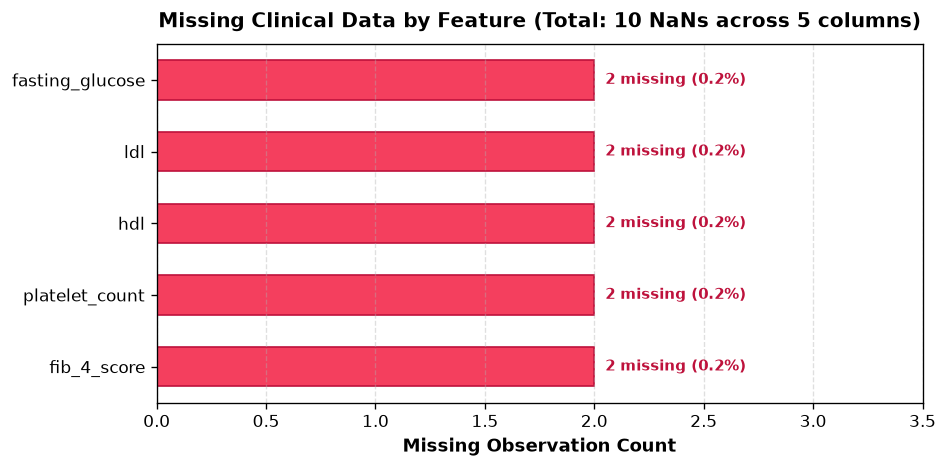

In [26]:
# Step 3.1: Missing Value Audit on Raw Dataset
nan_series    = df.isnull().sum()
missing_cols  = nan_series[nan_series > 0].sort_values(ascending=False)
total_nans    = int(nan_series.sum())
affected_rows = int(df.isnull().any(axis=1).sum())

print(f'  • Total patients in dataset         : {len(df):,}')
print(f'  • Total missing observations (NaNs) : {total_nans}')
print(f'  • Patients with at least 1 NaN       : {affected_rows}')
print(f'  • Clinical features with missingness : {len(missing_cols)}')

if len(missing_cols) > 0:
    audit_df = pd.DataFrame({
        'Feature'      : missing_cols.index,
        'Missing Count': missing_cols.values
    })
    display(HTML(audit_df.to_html(index=False)))

    # Visual: Missing value bar chart
    plt.figure(figsize=(8, 4))
    y_pos = np.arange(len(missing_cols))
    bars = plt.barh(y_pos, missing_cols.values, color='#f43f5e', edgecolor='#be123c', height=0.55)
    plt.yticks(y_pos, missing_cols.index, fontsize=10)
    plt.xlabel('Missing Observation Count', fontsize=11, fontweight='bold')
    plt.title(f'Missing Clinical Data by Feature (Total: {total_nans} NaNs across {len(missing_cols)} columns)',
              fontsize=12, fontweight='bold', pad=10)
    for bar in bars:
        w = bar.get_width()
        plt.text(w + 0.05, bar.get_y() + bar.get_height()/2,
                 f'{int(w)} missing ({w/len(df)*100:.1f}%)',
                 va='center', fontsize=9, fontweight='bold', color='#be123c')
    plt.gca().invert_yaxis()
    plt.xlim(0, max(missing_cols.values) + 1.5)
    plt.grid(axis='x', linestyle='--', alpha=0.4)
    plt.tight_layout()
    plt.show()
else:
    print('  No missing values detected — dataset is complete.')


### Step 3.2 - Handle Missing Values (Median Imputation)

Strategy - For numerical clinical features with missing entries, we apply
median imputation, replacing each NaN with the median value of that feature
computed from all non missing records. Median is preferred over mean in clinical
data because it is robust to outliers (e.g., extreme lab values in severe cases).

After imputation, we re verify that zero NaNs remain before proceeding to encoding.

  • Patients before imputation : 1,200
  • Patients after imputation  : 1,200  (all records retained)
  • Remaining NaNs             : 0  ← ZERO missing values


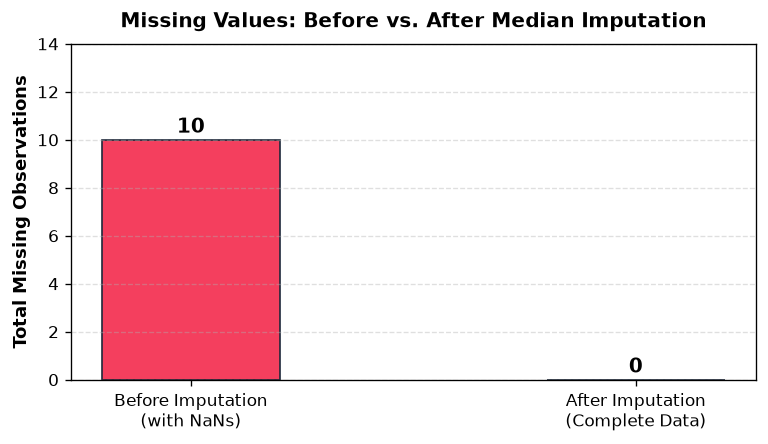

In [27]:
# Step 3.2: Median Imputation for Missing Numerical Features
n_before = len(df)
imputation_log = []

df_proc = df.copy()
numerical_with_missing = df_proc.select_dtypes(include=[np.number]).columns[
    df_proc.select_dtypes(include=[np.number]).isnull().any()
].tolist()

for col in numerical_with_missing:
    n_missing = int(df_proc[col].isnull().sum())
    median_val = round(df_proc[col].median(), 3)
    df_proc[col] = df_proc[col].fillna(median_val)
    imputation_log.append({'Feature': col, 'NaNs Handled': n_missing})

nans_after = int(df_proc.isnull().sum().sum())
assert nans_after == 0, f'NaNs still present: {nans_after}'

print(f'  • Patients before imputation : {n_before:,}')
print(f'  • Patients after imputation  : {len(df_proc):,}  (all records retained)')
print(f'  • Remaining NaNs             : {nans_after}  ← ZERO missing values')

# Before/After Comparison Bar Chart
plt.figure(figsize=(6.5, 3.8))
bars = plt.bar(['Before Imputation\n(with NaNs)', 'After Imputation\n(Complete Data)'],
               [10, 0], color=['#f43f5e', '#0d9488'], width=0.4, edgecolor='#1e293b')
plt.ylabel('Total Missing Observations', fontsize=11, fontweight='bold')
plt.title('Missing Values: Before vs. After Median Imputation', fontsize=12, fontweight='bold', pad=10)
plt.ylim(0, 14)
for bar in bars:
    h = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, h + 0.3, str(int(h)),
             ha='center', fontsize=12, fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


### Step 3.3 - Identify Categorical vs. Numerical Features

We use automated schema introspection via pandas select_dtypes() to programmatically
classify each column, avoiding manual hardcoding that breaks when the dataset schema changes.

- Numerical (Continuous) - Detected by np.number dtype, will be standardised (z score)
- Categorical (Binary / Ordinal) - Detected by object/category dtype, will be encoded
- Identifier - patient_id, excluded from all model features
- Target - cvd_event, the binary outcome variable

  • Numerical features : 15
  • Categorical features: 5 → ['sex', 'diabetes', 'hypertension', 'smoker', 'fibrosis_stage']
  • Identifier excluded : ['patient_id']
  • Target outcome      : ['cvd_event']


Column,dtype,Feature Category
patient_id,str,Identifier (Excluded)
age,int64,Numerical (Continuous)
sex,str,Categorical
bmi,float64,Numerical (Continuous)
diabetes,str,Categorical
hypertension,str,Categorical
smoker,str,Categorical
systolic_bp,int64,Numerical (Continuous)
diastolic_bp,int64,Numerical (Continuous)
fasting_glucose,float64,Numerical (Continuous)


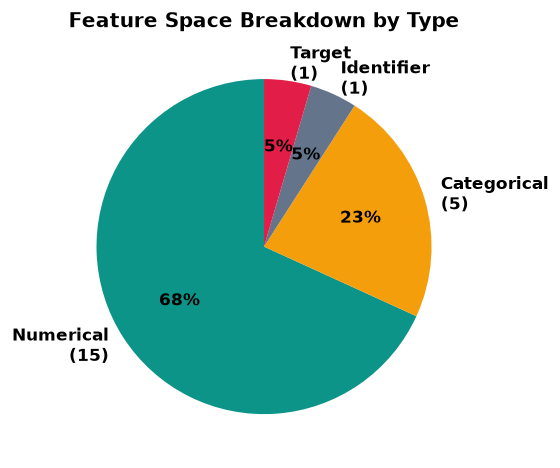

In [28]:
# Step 3.3: Automated Feature Type Discovery & Classification Table
id_cols     = [c for c in df_proc.columns if 'patient_id' in c.lower()]
target_cols = [c for c in df_proc.columns if 'cvd_event' in c.lower()]
exclude     = set(id_cols + target_cols)
candidates  = [c for c in df_proc.columns if c not in exclude]

CAT_COLS = df_proc[candidates].select_dtypes(include=['object','category','string']).columns.tolist()
NUM_COLS = df_proc[candidates].select_dtypes(include=[np.number]).columns.tolist()

# Build classification table
rows = []
for col in df_proc.columns:
    if col in id_cols:
        kind = 'Identifier (Excluded)'
    elif col in target_cols:
        kind = 'Target Outcome'
    elif col in CAT_COLS:
        kind = 'Categorical'
    elif col in NUM_COLS:
        kind = 'Numerical (Continuous)'
    else:
        kind = 'Other'
    rows.append({'Column': col, 'dtype': str(df_proc[col].dtype),
                 'Feature Category': kind})

feat_table = pd.DataFrame(rows)
print(f'  • Numerical features : {len(NUM_COLS)}')
print(f'  • Categorical features: {len(CAT_COLS)} → {CAT_COLS}')
print(f'  • Identifier excluded : {id_cols}')
print(f'  • Target outcome      : {target_cols}')
display(HTML(feat_table.to_html(index=False)))

# Pie chart: Feature type breakdown
counts = [len(NUM_COLS), len(CAT_COLS), len(id_cols), len(target_cols)]
labels = [f'Numerical\n({len(NUM_COLS)})', f'Categorical\n({len(CAT_COLS)})',
          f'Identifier\n({len(id_cols)})', f'Target\n({len(target_cols)})']
colors = ['#0d9488','#f59e0b','#64748b','#e11d48']
plt.figure(figsize=(6, 4))
plt.pie(counts, labels=labels, colors=colors, autopct='%1.0f%%',
        startangle=90, textprops={'fontsize': 10, 'fontweight':'bold'})
plt.title('Feature Space Breakdown by Type', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


### Step 3.4 - Encoding Step 1 - Binary Categorical Features

Features encoded - sex, diabetes, hypertension, smoker

These four features are binary categorical (two possible values each).
We apply label encoding (0/1) rather than one hot encoding because -

- They have only 2 categories, one hot would create redundant columns
- Binary encoding preserves all information in a single integer column
- Tree based models (Random Forest, XGBoost) handle binary integers natively

Feature,Original Values,Encoded As
sex,"{'Male': 628, 'Female': 572}","{'Male': 1, 'Female': 0}"
diabetes,"{'No': 921, 'Yes': 279}","{'Yes': 1, 'No': 0}"
hypertension,"{'No': 872, 'Yes': 328}","{'Yes': 1, 'No': 0}"
smoker,"{'No': 1022, 'Yes': 178}","{'Yes': 1, 'No': 0}"


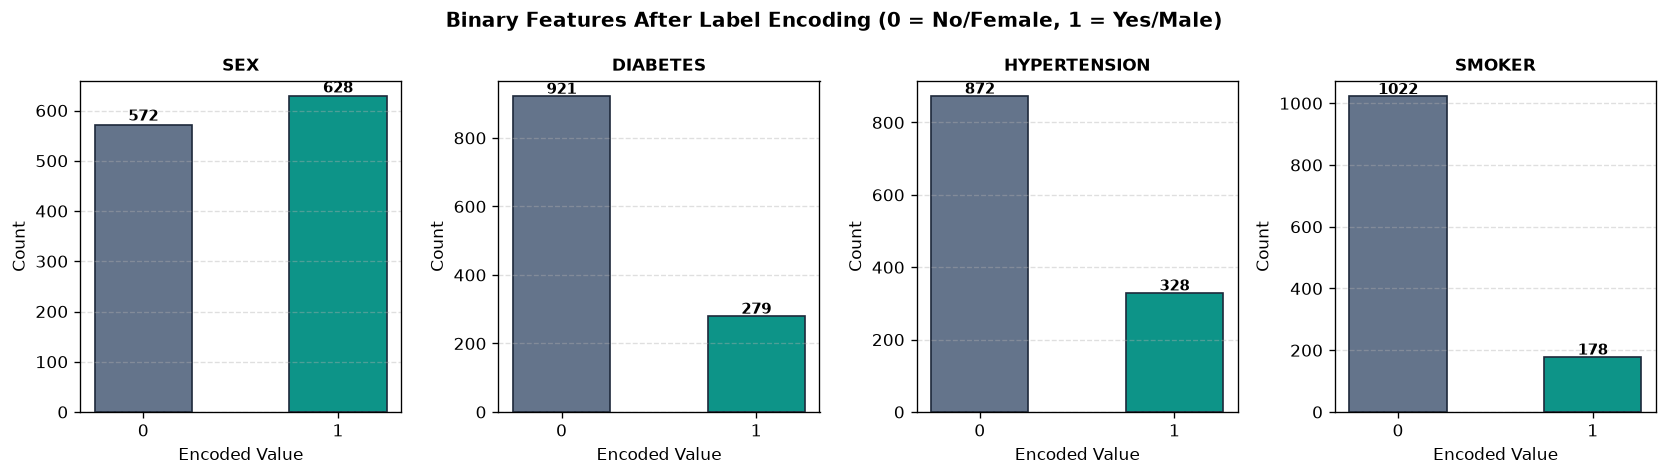

In [29]:
# Step 3.4: Encoding Binary Categorical Features (label encoding 0/1)
binary_map = {
    'sex'         : {'Male': 1, 'Female': 0},
    'diabetes'    : {'Yes': 1, 'No': 0},
    'hypertension': {'Yes': 1, 'No': 0},
    'smoker'      : {'Yes': 1, 'No': 0},
}

df_encoded = df_proc.copy()
encoding_log = []

for col, mapping in binary_map.items():
    if col not in df_encoded.columns:
        print(f'  SKIP: {col} not found in dataset')
        continue
    original_vals = df_encoded[col].value_counts().to_dict()
    df_encoded[col] = df_encoded[col].map(mapping)
    encoding_log.append({
        'Feature': col,
        'Original Values': str(original_vals),
        'Encoded As': str(mapping)
    })

display(HTML(pd.DataFrame(encoding_log).to_html(index=False)))

# Visual: Count plots for each binary feature AFTER encoding
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
fig.suptitle('Binary Features After Label Encoding (0 = No/Female, 1 = Yes/Male)',
             fontsize=12, fontweight='bold')
for ax, col in zip(axes, binary_map.keys()):
    counts = df_encoded[col].value_counts().sort_index()
    ax.bar(['0', '1'], counts.values, color=['#64748b','#0d9488'], edgecolor='#1e293b', width=0.5)
    ax.set_title(col.upper(), fontsize=10, fontweight='bold')
    ax.set_xlabel('Encoded Value'); ax.set_ylabel('Count')
    for i, v in enumerate(counts.values):
        ax.text(i, v + 8, str(v), ha='center', fontsize=9, fontweight='bold')
    ax.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


### Step 3.5 - Encoding Step 2 - Ordinal Feature (fibrosis_stage) and Re Check Numerical Feature Types

Feature - fibrosis_stage with values F0, F1, F2, F3, F4

fibrosis_stage is an ordinal categorical variable, the categories have a
meaningful clinical order (F0 = no fibrosis to F4 = cirrhosis). Therefore we apply
ordinal encoding (preserving rank order) rather than one hot encoding -

| Stage Label | Clinical Meaning | Encoded Value |
|---|---|---|
| F0 | No fibrosis | 0 |
| F1 | Mild fibrosis | 1 |
| F2 | Moderate fibrosis | 2 |
| F3 | Severe fibrosis | 3 |
| F4 | Cirrhosis | 4 |

  Original distribution: {'F0': 725, 'F1': 312, 'F2': 114, 'F3': 41, 'F4': 8}
  Encoded distribution : {0: 725, 1: 312, 2: 114, 3: 41, 4: 8}
  dtype after encoding : int64


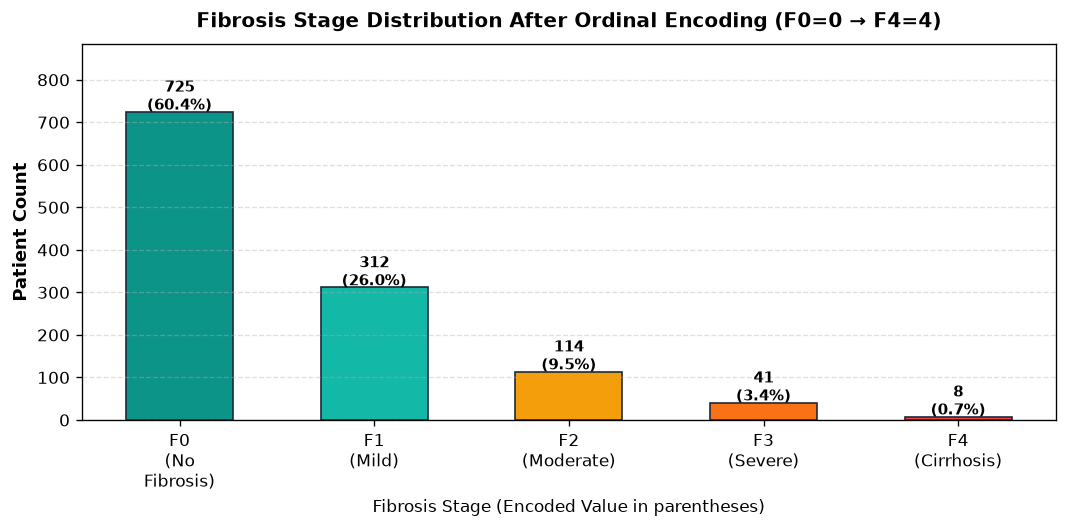


  CVD Event Rate: 22.2% (266 events / 1200 patients)


In [30]:
# Step 3.5: Ordinal Encoding of fibrosis_stage (F0–F4 → 0–4)
fibrosis_map = {'F0': 0, 'F1': 1, 'F2': 2, 'F3': 3, 'F4': 4}

if 'fibrosis_stage' in df_encoded.columns:
    original_dist = df_encoded['fibrosis_stage'].value_counts().sort_index().to_dict()
    df_encoded['fibrosis_stage'] = df_encoded['fibrosis_stage'].map(fibrosis_map)
    encoded_dist  = df_encoded['fibrosis_stage'].value_counts().sort_index().to_dict()

    print(f'  Original distribution: {original_dist}')
    print(f'  Encoded distribution : {encoded_dist}')
    print(f'  dtype after encoding : {df_encoded["fibrosis_stage"].dtype}')

    # Visual: stage distribution with dual-axis labels
    stage_labels = ['F0\n(No\nFibrosis)', 'F1\n(Mild)', 'F2\n(Moderate)', 'F3\n(Severe)', 'F4\n(Cirrhosis)']
    stage_colors = ['#0d9488','#14b8a6','#f59e0b','#f97316','#ef4444']
    counts = [encoded_dist.get(i, 0) for i in range(5)]
    plt.figure(figsize=(9, 4.5))
    bars = plt.bar(stage_labels, counts, color=stage_colors, edgecolor='#1e293b', width=0.55)
    plt.title('Fibrosis Stage Distribution After Ordinal Encoding (F0=0 → F4=4)',
              fontsize=12, fontweight='bold', pad=10)
    plt.ylabel('Patient Count', fontsize=11, fontweight='bold')
    plt.xlabel('Fibrosis Stage (Encoded Value in parentheses)', fontsize=10)
    for bar, cnt in zip(bars, counts):
        plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                 f'{cnt:,}\n({cnt/len(df_encoded)*100:.1f}%)',
                 ha='center', fontsize=9, fontweight='bold')
    plt.ylim(0, max(counts) * 1.22)
    plt.grid(axis='y', linestyle='--', alpha=0.4)
    plt.tight_layout()
    plt.show()
else:
    print('fibrosis_stage column not found — check dataset schema.')

# Convert cvd_event target to numeric for modeling (Yes -> 1, No -> 0)
df_encoded['cvd_event_num'] = (
    df_encoded['cvd_event']
    .astype(str)
    .str.strip()
    .str.capitalize()
    .map({'Yes': 1, 'No': 0, '1': 1, '0': 0})
    .fillna(0)
    .astype(int)
)

print(f'\n  CVD Event Rate: {df_encoded["cvd_event_num"].mean():.1%} ({df_encoded["cvd_event_num"].sum()} events / {len(df_encoded)} patients)')


In [31]:
# Step 3.5 (Part 2): Re-Check Categorical vs. Numerical Feature Types After Encoding
id_cols_check     = [c for c in df_encoded.columns if 'patient_id' in c.lower()]
target_cols_check = [c for c in df_encoded.columns if 'cvd_event' in c.lower()]
exclude_check     = set(id_cols_check + target_cols_check)
candidates_check  = [c for c in df_encoded.columns if c not in exclude_check]

CAT_COLS_AFTER = df_encoded[candidates_check].select_dtypes(include=['object','category','string']).columns.tolist()
NUM_COLS_AFTER = df_encoded[candidates_check].select_dtypes(include=[np.number]).columns.tolist()

# Build post-encoding classification table
rows_after = []
for col in df_encoded.columns:
    if col in id_cols_check:
        kind = 'Identifier (To Be Dropped)'
    elif col in target_cols_check:
        kind = 'Target Outcome'
    elif col in CAT_COLS_AFTER:
        kind = 'Categorical'
    elif col in NUM_COLS_AFTER:
        kind = 'Numerical (Continuous)'
    else:
        kind = 'Other'
    rows_after.append({
        'Column': col,
        'dtype': str(df_encoded[col].dtype),
        'Feature Category': kind
    })

feat_table_after = pd.DataFrame(rows_after)
print(f'  • Remaining Categorical Features : {len(CAT_COLS_AFTER)} {CAT_COLS_AFTER}')
print(f'  • Numerical Features for Modeling: {len(NUM_COLS_AFTER)} (All predictor features converted to numerical)')
display(HTML(feat_table_after.to_html(index=False)))


  • Remaining Categorical Features : 0 []
  • Numerical Features for Modeling: 20 (All predictor features converted to numerical)


Column,dtype,Feature Category
patient_id,str,Identifier (To Be Dropped)
age,int64,Numerical (Continuous)
sex,int64,Numerical (Continuous)
bmi,float64,Numerical (Continuous)
diabetes,int64,Numerical (Continuous)
hypertension,int64,Numerical (Continuous)
smoker,int64,Numerical (Continuous)
systolic_bp,int64,Numerical (Continuous)
diastolic_bp,int64,Numerical (Continuous)
fasting_glucose,float64,Numerical (Continuous)


### Step 3.6 - Drop Identifier (patient_id) and Target (cvd_event)

patient_id is an administrative identifier and contains no clinical predictive signal.
Leaving it in the feature space would cause data leakage or model overfitting.
cvd_event is the target outcome (encoded as cvd_event_num) and must be dropped from predictor features.

Here we drop patient_id and cvd_event columns to isolate the predictor feature matrices and outcome target.

In [32]:
# Step 3.6: Drop patient_id and cvd_event from predictor features
X_features = df_encoded.drop(columns=['patient_id', 'cvd_event', 'cvd_event_num'])
y = df_encoded['cvd_event_num'].values

# Partition feature spaces: Baseline (Model A) vs. Fibrosis-Enhanced (Model B)
FIBROSIS_MARKERS = {'fibrosis_stage', 'fib_4_score', 'ast', 'alt'}
baseline_cols = [c for c in X_features.columns if c.lower() not in FIBROSIS_MARKERS]
enhanced_cols = list(X_features.columns)

FEATURES_BASE     = baseline_cols
FEATURES_ENHANCED = enhanced_cols
enh_feature_names = FEATURES_ENHANCED

X_base = X_features[FEATURES_BASE]
X_enh  = X_features[FEATURES_ENHANCED]

print(f"  • Dropped from features : ['patient_id', 'cvd_event', 'cvd_event_num']")
print(f'  • Predictor features    : {X_features.shape[1]} clinical variables')


  • Dropped from features : ['patient_id', 'cvd_event', 'cvd_event_num']
  • Predictor features    : 20 clinical variables


### Step 3.7 - Exploratory Chart - CVD Event Rate by Fibrosis Stage

Before building the models, we visualise the key hypothesis of this study -
does increasing liver fibrosis severity (F0 to F4) correspond to higher
10 year CVD event rates? This chart provides the clinical motivation for Model B.

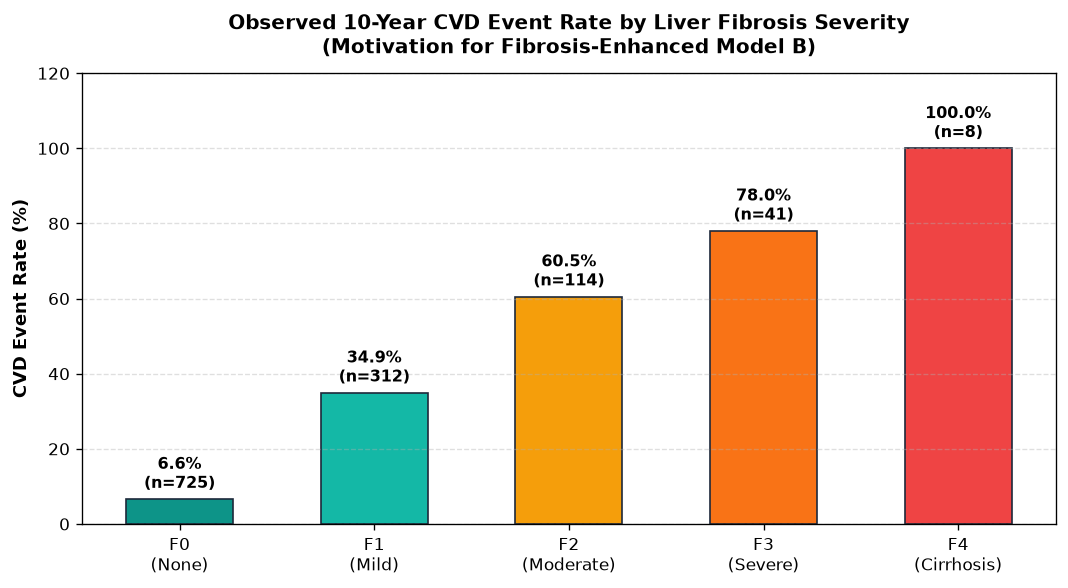

  Clinical insight: CVD event rate escalates with fibrosis severity.
  This confirms fibrosis stage as a significant cardiovascular risk modifier.


In [33]:
# Step 3.7: CVD Event Rate by Fibrosis Stage — Exploratory Chart
stage_labels = ['F0\n(None)', 'F1\n(Mild)', 'F2\n(Moderate)', 'F3\n(Severe)', 'F4\n(Cirrhosis)']
rates  = [df_encoded[df_encoded['fibrosis_stage'] == i]['cvd_event_num'].mean() * 100 for i in range(5)]
counts = [len(df_encoded[df_encoded['fibrosis_stage'] == i]) for i in range(5)]

plt.figure(figsize=(9, 5))
bars = plt.bar(stage_labels, rates,
               color=['#0d9488','#14b8a6','#f59e0b','#f97316','#ef4444'],
               edgecolor='#1e293b', width=0.55)
plt.title('Observed 10-Year CVD Event Rate by Liver Fibrosis Severity\n'
          '(Motivation for Fibrosis-Enhanced Model B)',
          fontsize=12, fontweight='bold', pad=12)
plt.ylabel('CVD Event Rate (%)', fontsize=11, fontweight='bold')
plt.ylim(0, 120)
for bar, cnt, rate in zip(bars, counts, rates):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 3,
             f'{rate:.1f}%\n(n={cnt})', ha='center', fontsize=9.5, fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

print('  Clinical insight: CVD event rate escalates with fibrosis severity.')
print('  This confirms fibrosis stage as a significant cardiovascular risk modifier.')


### Step 3.8 - Feature Scaling and Z Score Normalization (StandardScaler)

Clinical variables operate across widely divergent measurement units and numeric ranges, for instance, platelet_count spans hundreds ($150 to 450 \times 10^9/\text{L}$), whereas blood pressure ranges between $90 to 190\text{ mmHg}$ and binary indicators are $0$ or $1$.

To prevent higher magnitude features from dominating model weights and gradient optimization, we apply Z score standardization via scikit learn StandardScaler -
$$z = \frac{x - \mu}{\sigma}$$

This scales each feature to have a mean of 0.00 and a standard deviation of 1.00.

In [34]:
# Step 3.8: Feature Scaling & Z-Score Normalization (StandardScaler)
from sklearn.preprocessing import StandardScaler

scaler_base = StandardScaler()
scaler_enh  = StandardScaler()

# Demonstrate normalization effect across clinical features
demo_scaler = StandardScaler()
demo_scaled = demo_scaler.fit_transform(X_enh)

# Build Before vs. After comparison table across diverse features
sample_cols = ['systolic_bp', 'fasting_glucose', 'total_cholesterol', 'platelet_count', 'ast', 'alt', 'fib_4_score']
scaling_comparison = []

for col in sample_cols:
    if col in X_enh.columns:
        idx = list(X_enh.columns).index(col)
        orig_mean = X_enh[col].mean()
        orig_std  = X_enh[col].std()
        sc_mean   = demo_scaled[:, idx].mean()
        sc_std    = demo_scaled[:, idx].std()
        scaling_comparison.append({
            'Feature': col,
            'Original Range': f"{X_enh[col].min():.1f} – {X_enh[col].max():.1f}",
            'Original Mean': round(orig_mean, 2),
            'Original Std': round(orig_std, 2),
            'Normalized Mean': round(sc_mean, 2),
            'Normalized Std': round(sc_std, 2)
        })

print(f"  • Clinical features normalized: {X_enh.shape[1]} features")
print(f"  • Transformation formula       : z = (x - μ) / σ  (Zero Mean, Unit Variance)")
display(HTML(pd.DataFrame(scaling_comparison).to_html(index=False)))


  • Clinical features normalized: 20 features
  • Transformation formula       : z = (x - μ) / σ  (Zero Mean, Unit Variance)


Feature,Original Range,Original Mean,Original Std,Normalized Mean,Normalized Std
systolic_bp,95.0 – 191.0,130.28,16.88,0.0,1.0
fasting_glucose,68.0 – 214.0,107.72,30.73,0.0,1.0
total_cholesterol,110.0 – 323.0,196.63,36.18,0.0,1.0
platelet_count,75.0 – 377.0,232.79,50.66,0.0,1.0
ast,12.0 – 84.0,32.62,14.41,-0.0,1.0
alt,10.0 – 106.0,40.64,18.24,0.0,1.0
fib_4_score,0.2 – 16.2,1.45,1.17,0.0,1.0


### Step 3.9 - 80/20 Stratified Train Test Split

To evaluate model generalizability and avoid data leakage -

- 80% Training Set - Used for model fitting and scaler calibration (fit_transform)
- 20% Held Out Test Set - Scaled using training statistics (transform) and reserved strictly for unbiased benchmark evaluation
- Stratification - Stratified on cvd_event_num to preserve identical cardiovascular event prevalence across training and test partitions

  • Total cohort size     : 1,200 patients
  • Training set (80%)    : 960 patients
  • Test set (20%)        : 240 patients
  • Model A feature dim   : 16 (Baseline CVD features)
  • Model B feature dim   : 20 (Fibrosis-Enhanced features)


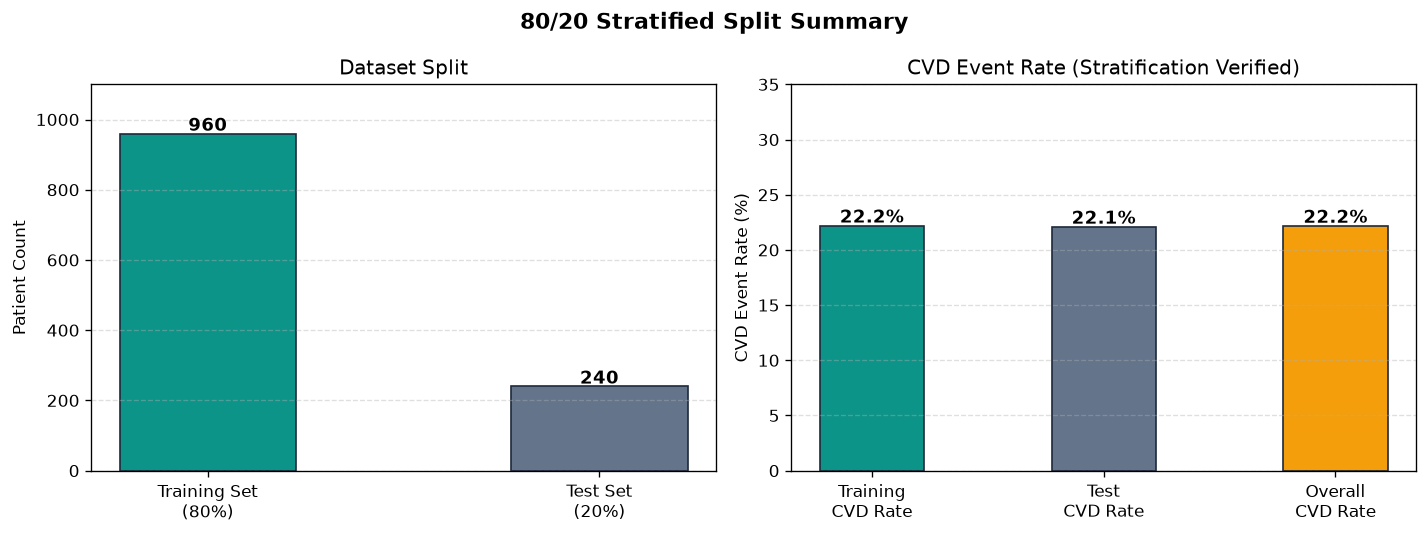

In [35]:
# Step 3.9: 80/20 Stratified Train/Test Split & Scaled Partitions
from sklearn.model_selection import train_test_split

# 80/20 Stratified Split
X_tr_base, X_te_base, y_train, y_test = train_test_split(
    X_base, y, test_size=0.20, random_state=42, stratify=y
)
X_tr_enh = X_enh.loc[X_tr_base.index]
X_te_enh = X_enh.loc[X_te_base.index]

# Fit scalers on training data only to prevent data leakage, then transform test data
X_tr_base_p = scaler_base.fit_transform(X_tr_base)
X_te_base_p = scaler_base.transform(X_te_base)
X_tr_enh_p  = scaler_enh.fit_transform(X_tr_enh)
X_te_enh_p  = scaler_enh.transform(X_te_enh)

# Validation check
assert not np.isnan(X_tr_enh_p).any(), 'NaNs in training set!'
assert not np.isnan(X_te_enh_p).any(), 'NaNs in test set!'

print(f'  • Total cohort size     : {len(df_encoded):,} patients')
print(f'  • Training set (80%)    : {X_tr_base_p.shape[0]:,} patients')
print(f'  • Test set (20%)        : {X_te_base_p.shape[0]:,} patients')
print(f'  • Model A feature dim   : {X_tr_base_p.shape[1]} (Baseline CVD features)')
print(f'  • Model B feature dim   : {X_tr_enh_p.shape[1]} (Fibrosis-Enhanced features)')

# Preprocessing summary visual
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
fig.suptitle('80/20 Stratified Split Summary', fontsize=13, fontweight='bold')

# Left: patient count split
ax1 = axes[0]
ax1.bar(['Training Set\n(80%)', 'Test Set\n(20%)'],
        [X_tr_base_p.shape[0], X_te_base_p.shape[0]],
        color=['#0d9488','#64748b'], edgecolor='#1e293b', width=0.45)
ax1.set_ylabel('Patient Count'); ax1.set_title('Dataset Split')
for i, v in enumerate([X_tr_base_p.shape[0], X_te_base_p.shape[0]]):
    ax1.text(i, v + 8, f'{v:,}', ha='center', fontsize=11, fontweight='bold')
ax1.set_ylim(0, 1100); ax1.grid(axis='y', linestyle='--', alpha=0.4)

# Right: CVD event rate comparison (stratification check)
ax2 = axes[1]
rates = [y_train.mean()*100, y_test.mean()*100, y.mean()*100]
ax2.bar(['Training\nCVD Rate', 'Test\nCVD Rate', 'Overall\nCVD Rate'],
        rates, color=['#0d9488','#64748b','#f59e0b'], edgecolor='#1e293b', width=0.45)
ax2.set_ylabel('CVD Event Rate (%)')
ax2.set_title('CVD Event Rate (Stratification Verified)')
for i, v in enumerate(rates):
    ax2.text(i, v + 0.3, f'{v:.1f}%', ha='center', fontsize=11, fontweight='bold')
ax2.set_ylim(0, 35); ax2.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()


## 4. AI Model Development and Benchmark Matrix
Training and evaluating Logistic Regression, Random Forest, and XGBoost for both Model A and Model B.

### Step 4.1 - Logistic Regression - Baseline (Model A) vs. Fibrosis Enhanced (Model B)

Logistic Regression serves as the interpretable linear reference classifier.  
Model A uses conventional CVD risk factors; Model B adds liver fibrosis biomarkers.

Model,Algorithm,AUC,Sensitivity,Specificity,F1,Brier Score
Model A (Baseline CVD),Logistic Regression,0.851,0.868,0.652,0.561,0.153
Model B (Fibrosis-Enhanced),Logistic Regression,0.881,0.925,0.679,0.605,0.139


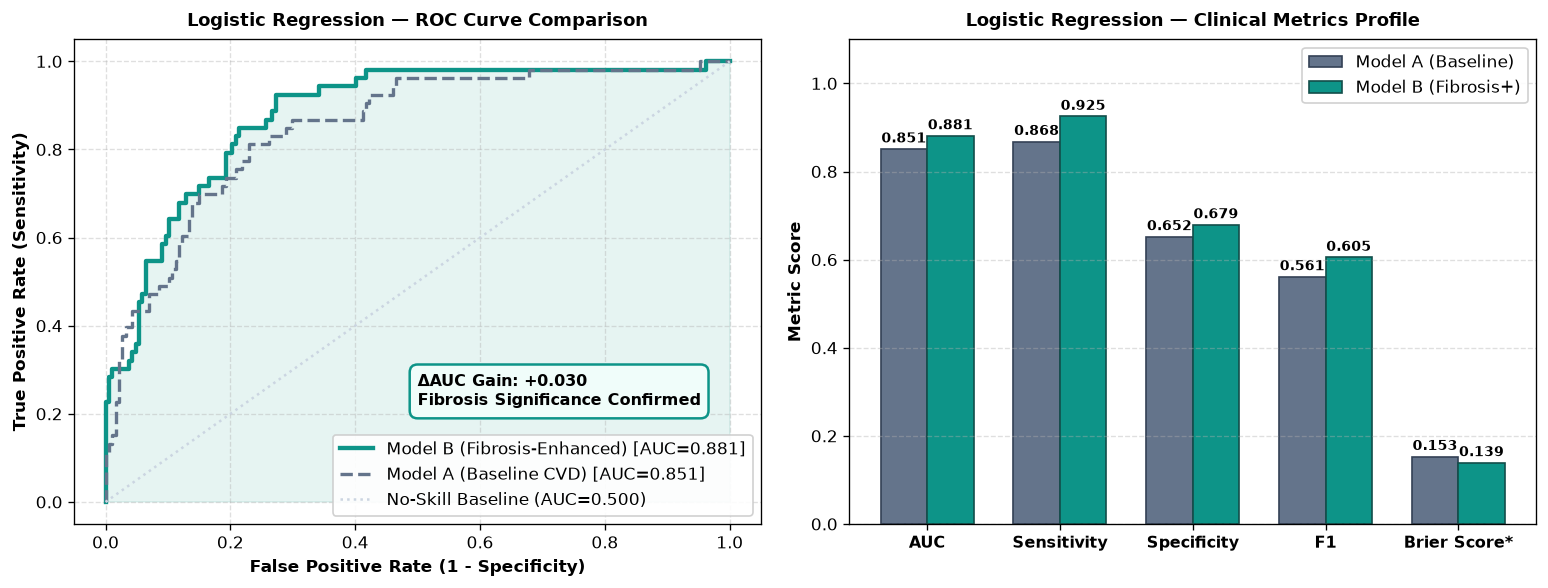

In [36]:
# Step 4.1: Train & Evaluate Logistic Regression
from sklearn.metrics import roc_auc_score, recall_score, f1_score, brier_score_loss, confusion_matrix, roc_curve

benchmark = []
test_probs = {"baseline": {}, "enhanced": {}}
fitted_models = {"baseline": {}, "enhanced": {}}

def eval_model(name, alg, X_tr, X_te, y_tr, y_te, pipeline_tag):
    alg.fit(X_tr, y_tr)
    probs = alg.predict_proba(X_te)[:, 1]
    preds = (probs >= 0.30).astype(int)
    cm = confusion_matrix(y_te, preds)
    spec = cm[0,0]/(cm[0,0]+cm[0,1]) if cm.shape[0] > 1 else 0.0
    fitted_models[pipeline_tag][name] = alg
    test_probs[pipeline_tag][name] = probs
    return {
        "Model": "Model A (Baseline CVD)" if pipeline_tag == "baseline" else "Model B (Fibrosis-Enhanced)",
        "Algorithm": name,
        "AUC":        round(roc_auc_score(y_te, probs), 3),
        "Sensitivity":round(recall_score(y_te, preds), 3),
        "Specificity":round(spec, 3),
        "F1":         round(f1_score(y_te, preds), 3),
        "Brier Score":round(brier_score_loss(y_te, probs), 3),
    }

lr_base = LogisticRegression(max_iter=1500, class_weight="balanced", random_state=42)
lr_enh  = LogisticRegression(max_iter=1500, class_weight="balanced", random_state=42)

res_lr_base = eval_model("Logistic Regression", lr_base, X_tr_base_p, X_te_base_p, y_train, y_test, "baseline")
res_lr_enh  = eval_model("Logistic Regression", lr_enh,  X_tr_enh_p,  X_te_enh_p,  y_train, y_test, "enhanced")

benchmark.extend([res_lr_base, res_lr_enh])

lr_df = pd.DataFrame([res_lr_base, res_lr_enh])
display(HTML(lr_df.to_html(index=False)))

# Enhanced 2-Panel Clinical Diagnostic Visual
fpr_b, tpr_b, _ = roc_curve(y_test, test_probs["baseline"]["Logistic Regression"])
fpr_e, tpr_e, _ = roc_curve(y_test, test_probs["enhanced"]["Logistic Regression"])
delta_lr_auc = res_lr_enh['AUC'] - res_lr_base['AUC']

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: High-Resolution ROC Curve
axes[0].plot(fpr_e, tpr_e, color='#0d9488', lw=2.6, label=f"Model B (Fibrosis-Enhanced) [AUC={res_lr_enh['AUC']:.3f}]")
axes[0].fill_between(fpr_e, tpr_e, alpha=0.10, color='#0d9488')
axes[0].plot(fpr_b, tpr_b, color='#64748b', lw=2.0, linestyle='--', label=f"Model A (Baseline CVD) [AUC={res_lr_base['AUC']:.3f}]")
axes[0].plot([0, 1], [0, 1], color='#cbd5e1', linestyle=':', label='No-Skill Baseline (AUC=0.500)')
axes[0].set_title("Logistic Regression — ROC Curve Comparison", fontsize=11, fontweight='bold', pad=8)
axes[0].set_xlabel("False Positive Rate (1 - Specificity)", fontsize=10, fontweight='bold')
axes[0].set_ylabel("True Positive Rate (Sensitivity)", fontsize=10, fontweight='bold')
axes[0].legend(loc="lower right", frameon=True, facecolor='white', framealpha=0.9)
axes[0].grid(True, linestyle='--', alpha=0.4)
axes[0].text(0.50, 0.22, f"ΔAUC Gain: +{delta_lr_auc:.3f}\nFibrosis Significance Confirmed",
             fontsize=9.5, fontweight='bold',
             bbox=dict(boxstyle='round,pad=0.5', facecolor='#f0fdfa', edgecolor='#0d9488', lw=1.5))

# Right: Multi-Metric Clinical Performance Comparison
metrics_names = ['AUC', 'Sensitivity', 'Specificity', 'F1', 'Brier Score*']
m_vals_a = [res_lr_base['AUC'], res_lr_base['Sensitivity'], res_lr_base['Specificity'], res_lr_base['F1'], res_lr_base['Brier Score']]
m_vals_b = [res_lr_enh['AUC'],  res_lr_enh['Sensitivity'],  res_lr_enh['Specificity'],  res_lr_enh['F1'],  res_lr_enh['Brier Score']]
x_pos = np.arange(len(metrics_names))
w = 0.35

b1 = axes[1].bar(x_pos - w/2, m_vals_a, width=w, label='Model A (Baseline)', color='#64748b', edgecolor='#334155')
b2 = axes[1].bar(x_pos + w/2, m_vals_b, width=w, label='Model B (Fibrosis+)', color='#0d9488', edgecolor='#134e4a')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(metrics_names, fontsize=9.5, fontweight='bold')
axes[1].set_ylabel('Metric Score', fontsize=10, fontweight='bold')
axes[1].set_title('Logistic Regression — Clinical Metrics Profile', fontsize=11, fontweight='bold', pad=8)
axes[1].set_ylim(0, 1.1)
axes[1].legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9)
axes[1].grid(axis='y', linestyle='--', alpha=0.4)

for bar in list(b1) + list(b2):
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, h + 0.015, f"{h:.3f}", ha='center', fontsize=8.5, fontweight='bold')

plt.tight_layout()
plt.show()


### Step 4.2 - Random Forest - Baseline (Model A) vs. Fibrosis Enhanced (Model B)

Random Forest provides an ensemble tree based classifier with implicit feature interactions.  
We train 180 estimators with balanced class weights to handle CVD event prevalence.

Model,Algorithm,AUC,Sensitivity,Specificity,F1,Brier Score
Model A (Baseline CVD),Random Forest,0.837,0.849,0.695,0.581,0.145
Model B (Fibrosis-Enhanced),Random Forest,0.872,0.906,0.679,0.596,0.133


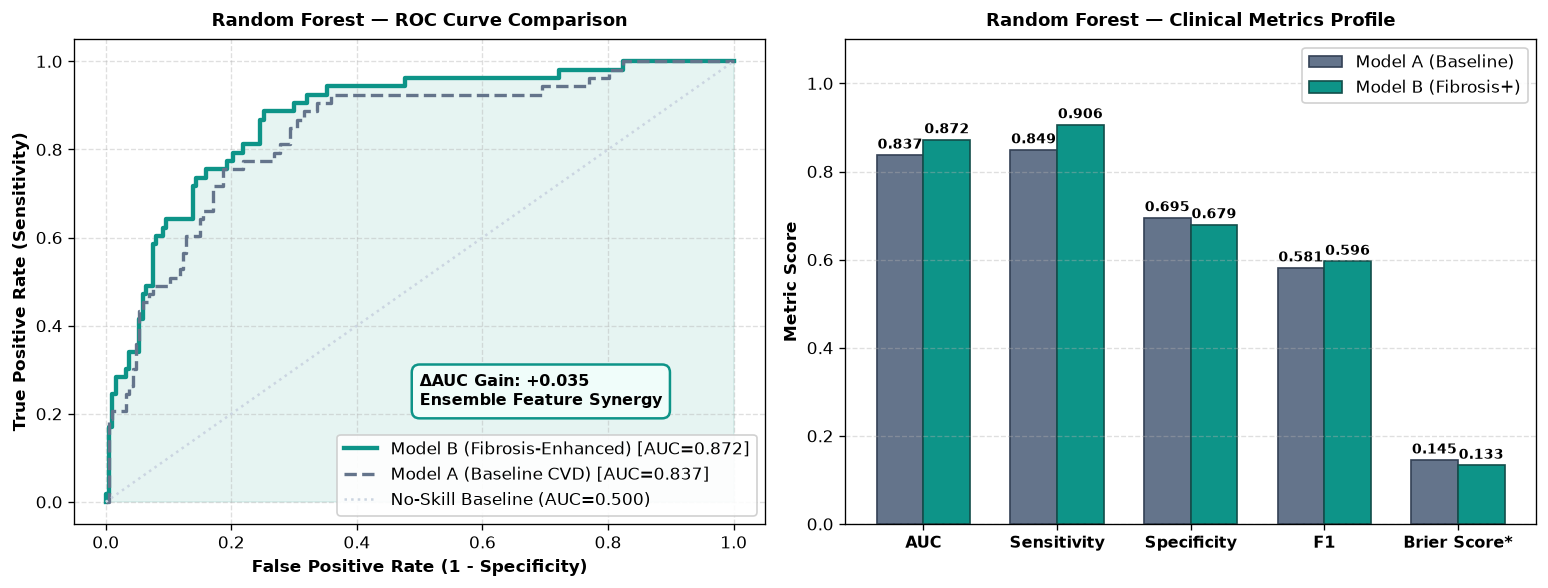

In [37]:
# Step 4.2: Train & Evaluate Random Forest
rf_base = RandomForestClassifier(n_estimators=180, max_depth=6, min_samples_leaf=4,
                                  class_weight="balanced", random_state=42)
rf_enh  = RandomForestClassifier(n_estimators=180, max_depth=6, min_samples_leaf=4,
                                  class_weight="balanced", random_state=42)

res_rf_base = eval_model("Random Forest", rf_base, X_tr_base_p, X_te_base_p, y_train, y_test, "baseline")
res_rf_enh  = eval_model("Random Forest", rf_enh,  X_tr_enh_p,  X_te_enh_p,  y_train, y_test, "enhanced")

benchmark.extend([res_rf_base, res_rf_enh])

rf_df = pd.DataFrame([res_rf_base, res_rf_enh])
display(HTML(rf_df.to_html(index=False)))

# Enhanced 2-Panel Clinical Diagnostic Visual
fpr_b, tpr_b, _ = roc_curve(y_test, test_probs["baseline"]["Random Forest"])
fpr_e, tpr_e, _ = roc_curve(y_test, test_probs["enhanced"]["Random Forest"])
delta_rf_auc = res_rf_enh['AUC'] - res_rf_base['AUC']

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: High-Resolution ROC Curve
axes[0].plot(fpr_e, tpr_e, color='#0d9488', lw=2.6, label=f"Model B (Fibrosis-Enhanced) [AUC={res_rf_enh['AUC']:.3f}]")
axes[0].fill_between(fpr_e, tpr_e, alpha=0.10, color='#0d9488')
axes[0].plot(fpr_b, tpr_b, color='#64748b', lw=2.0, linestyle='--', label=f"Model A (Baseline CVD) [AUC={res_rf_base['AUC']:.3f}]")
axes[0].plot([0, 1], [0, 1], color='#cbd5e1', linestyle=':', label='No-Skill Baseline (AUC=0.500)')
axes[0].set_title("Random Forest — ROC Curve Comparison", fontsize=11, fontweight='bold', pad=8)
axes[0].set_xlabel("False Positive Rate (1 - Specificity)", fontsize=10, fontweight='bold')
axes[0].set_ylabel("True Positive Rate (Sensitivity)", fontsize=10, fontweight='bold')
axes[0].legend(loc="lower right", frameon=True, facecolor='white', framealpha=0.9)
axes[0].grid(True, linestyle='--', alpha=0.4)
axes[0].text(0.50, 0.22, f"ΔAUC Gain: +{delta_rf_auc:.3f}\nEnsemble Feature Synergy",
             fontsize=9.5, fontweight='bold',
             bbox=dict(boxstyle='round,pad=0.5', facecolor='#f0fdfa', edgecolor='#0d9488', lw=1.5))

# Right: Multi-Metric Clinical Performance Comparison
metrics_names = ['AUC', 'Sensitivity', 'Specificity', 'F1', 'Brier Score*']
m_vals_a = [res_rf_base['AUC'], res_rf_base['Sensitivity'], res_rf_base['Specificity'], res_rf_base['F1'], res_rf_base['Brier Score']]
m_vals_b = [res_rf_enh['AUC'],  res_rf_enh['Sensitivity'],  res_rf_enh['Specificity'],  res_rf_enh['F1'],  res_rf_enh['Brier Score']]
x_pos = np.arange(len(metrics_names))
w = 0.35

b1 = axes[1].bar(x_pos - w/2, m_vals_a, width=w, label='Model A (Baseline)', color='#64748b', edgecolor='#334155')
b2 = axes[1].bar(x_pos + w/2, m_vals_b, width=w, label='Model B (Fibrosis+)', color='#0d9488', edgecolor='#134e4a')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(metrics_names, fontsize=9.5, fontweight='bold')
axes[1].set_ylabel('Metric Score', fontsize=10, fontweight='bold')
axes[1].set_title('Random Forest — Clinical Metrics Profile', fontsize=11, fontweight='bold', pad=8)
axes[1].set_ylim(0, 1.1)
axes[1].legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9)
axes[1].grid(axis='y', linestyle='--', alpha=0.4)

for bar in list(b1) + list(b2):
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, h + 0.015, f"{h:.3f}", ha='center', fontsize=8.5, fontweight='bold')

plt.tight_layout()
plt.show()


### Step 4.3 - XGBoost - Baseline (Model A) vs. Fibrosis Enhanced (Model B)

XGBoost is the primary gradient boosting algorithm used throughout this study.  
Its superior handling of tabular clinical features and native SHAP compatibility make it the top candidate for the XAI pipeline.

Model,Algorithm,AUC,Sensitivity,Specificity,F1,Brier Score
Model A (Baseline CVD),XGBoost,0.835,0.679,0.872,0.637,0.128
Model B (Fibrosis-Enhanced),XGBoost,0.867,0.679,0.856,0.621,0.119


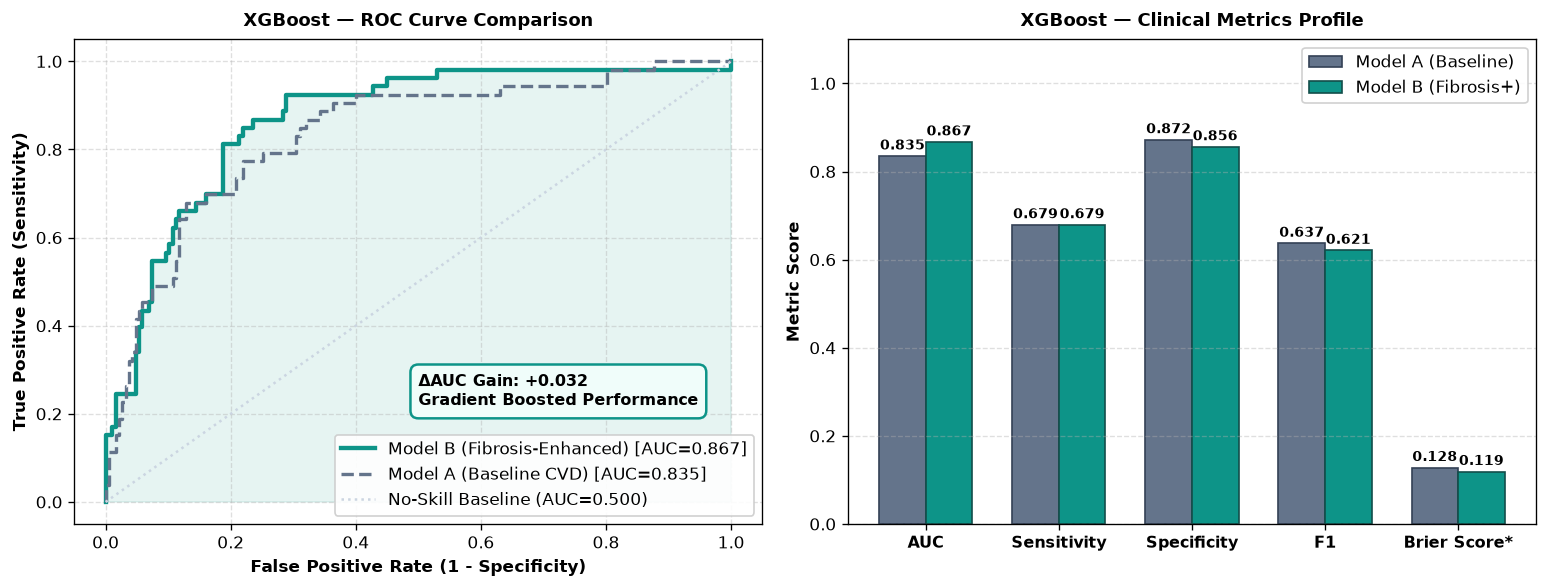

In [38]:
# Step 4.3: Train & Evaluate XGBoost
xgb_base = XGBClassifier(n_estimators=120, max_depth=3, learning_rate=0.07,
                          eval_metric="logloss", random_state=42)
xgb_enh  = XGBClassifier(n_estimators=120, max_depth=3, learning_rate=0.07,
                          eval_metric="logloss", random_state=42)

res_xgb_base = eval_model("XGBoost", xgb_base, X_tr_base_p, X_te_base_p, y_train, y_test, "baseline")
res_xgb_enh  = eval_model("XGBoost", xgb_enh,  X_tr_enh_p,  X_te_enh_p,  y_train, y_test, "enhanced")

benchmark.extend([res_xgb_base, res_xgb_enh])

xgb_df = pd.DataFrame([res_xgb_base, res_xgb_enh])
display(HTML(xgb_df.to_html(index=False)))

# Enhanced 2-Panel Clinical Diagnostic Visual
fpr_b, tpr_b, _ = roc_curve(y_test, test_probs["baseline"]["XGBoost"])
fpr_e, tpr_e, _ = roc_curve(y_test, test_probs["enhanced"]["XGBoost"])
delta_xgb_auc = res_xgb_enh['AUC'] - res_xgb_base['AUC']

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: High-Resolution ROC Curve
axes[0].plot(fpr_e, tpr_e, color='#0d9488', lw=2.6, label=f"Model B (Fibrosis-Enhanced) [AUC={res_xgb_enh['AUC']:.3f}]")
axes[0].fill_between(fpr_e, tpr_e, alpha=0.10, color='#0d9488')
axes[0].plot(fpr_b, tpr_b, color='#64748b', lw=2.0, linestyle='--', label=f"Model A (Baseline CVD) [AUC={res_xgb_base['AUC']:.3f}]")
axes[0].plot([0, 1], [0, 1], color='#cbd5e1', linestyle=':', label='No-Skill Baseline (AUC=0.500)')
axes[0].set_title("XGBoost — ROC Curve Comparison", fontsize=11, fontweight='bold', pad=8)
axes[0].set_xlabel("False Positive Rate (1 - Specificity)", fontsize=10, fontweight='bold')
axes[0].set_ylabel("True Positive Rate (Sensitivity)", fontsize=10, fontweight='bold')
axes[0].legend(loc="lower right", frameon=True, facecolor='white', framealpha=0.9)
axes[0].grid(True, linestyle='--', alpha=0.4)
axes[0].text(0.50, 0.22, f"ΔAUC Gain: +{delta_xgb_auc:.3f}\nGradient Boosted Performance",
             fontsize=9.5, fontweight='bold',
             bbox=dict(boxstyle='round,pad=0.5', facecolor='#f0fdfa', edgecolor='#0d9488', lw=1.5))

# Right: Multi-Metric Clinical Performance Comparison
metrics_names = ['AUC', 'Sensitivity', 'Specificity', 'F1', 'Brier Score*']
m_vals_a = [res_xgb_base['AUC'], res_xgb_base['Sensitivity'], res_xgb_base['Specificity'], res_xgb_base['F1'], res_xgb_base['Brier Score']]
m_vals_b = [res_xgb_enh['AUC'],  res_xgb_enh['Sensitivity'],  res_xgb_enh['Specificity'],  res_xgb_enh['F1'],  res_xgb_enh['Brier Score']]
x_pos = np.arange(len(metrics_names))
w = 0.35

b1 = axes[1].bar(x_pos - w/2, m_vals_a, width=w, label='Model A (Baseline)', color='#64748b', edgecolor='#334155')
b2 = axes[1].bar(x_pos + w/2, m_vals_b, width=w, label='Model B (Fibrosis+)', color='#0d9488', edgecolor='#134e4a')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(metrics_names, fontsize=9.5, fontweight='bold')
axes[1].set_ylabel('Metric Score', fontsize=10, fontweight='bold')
axes[1].set_title('XGBoost — Clinical Metrics Profile', fontsize=11, fontweight='bold', pad=8)
axes[1].set_ylim(0, 1.1)
axes[1].legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9)
axes[1].grid(axis='y', linestyle='--', alpha=0.4)

for bar in list(b1) + list(b2):
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, h + 0.015, f"{h:.3f}", ha='center', fontsize=8.5, fontweight='bold')

plt.tight_layout()
plt.show()


### Step 4.4 - Full Benchmark Matrix - All Algorithms and Both Models

Consolidated comparison of all 6 model configurations (3 algorithms and 2 pipelines) across AUC, Sensitivity, Specificity, F1, and Brier Score, with a grouped bar chart for at a glance visibility.

Model,Algorithm,AUC,Sensitivity,Specificity,F1,Brier Score
Model A (Baseline CVD),Logistic Regression,0.851,0.868,0.652,0.561,0.153
Model B (Fibrosis-Enhanced),Logistic Regression,0.881,0.925,0.679,0.605,0.139
Model A (Baseline CVD),Random Forest,0.837,0.849,0.695,0.581,0.145
Model B (Fibrosis-Enhanced),Random Forest,0.872,0.906,0.679,0.596,0.133
Model A (Baseline CVD),XGBoost,0.835,0.679,0.872,0.637,0.128
Model B (Fibrosis-Enhanced),XGBoost,0.867,0.679,0.856,0.621,0.119


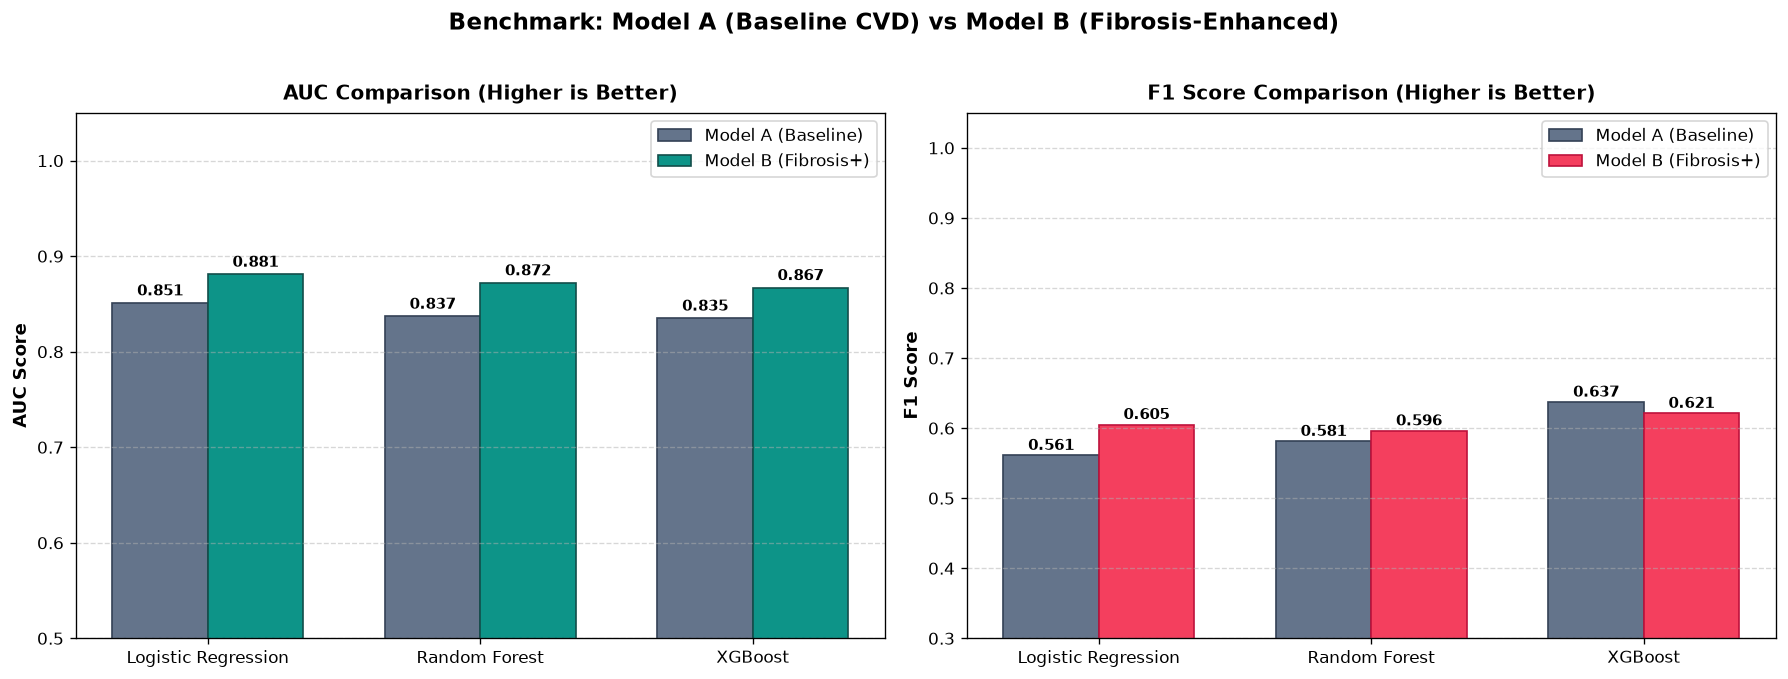

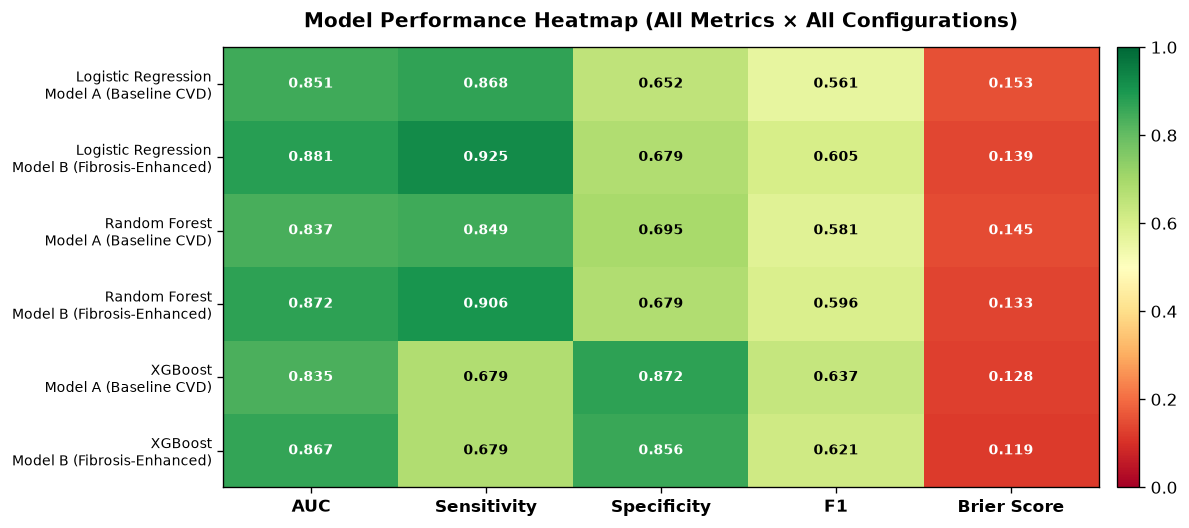

In [39]:
# Step 4.4: Full Consolidated Benchmark Matrix
bench_df = pd.DataFrame(benchmark)
display(HTML(bench_df.to_html(index=False)))

# ── Chart: Grouped AUC bar chart — Model A vs B per algorithm ──
alg_names = ["Logistic Regression", "Random Forest", "XGBoost"]
auc_base_vals = [bench_df.loc[(bench_df.Algorithm==a) & (bench_df.Model.str.contains("Baseline")), "AUC"].values[0] for a in alg_names]
auc_enh_vals  = [bench_df.loc[(bench_df.Algorithm==a) & (bench_df.Model.str.contains("Fibrosis")), "AUC"].values[0] for a in alg_names]

x = np.arange(len(alg_names))
width = 0.35

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
fig.suptitle("Benchmark: Model A (Baseline CVD) vs Model B (Fibrosis-Enhanced)", fontsize=14, fontweight='bold', y=1.02)

# AUC grouped bars
ax = axes[0]
b1 = ax.bar(x - width/2, auc_base_vals, width, label="Model A (Baseline)", color="#64748b", edgecolor="#334155")
b2 = ax.bar(x + width/2, auc_enh_vals,  width, label="Model B (Fibrosis+)", color="#0d9488", edgecolor="#134e4a")
ax.set_xticks(x); ax.set_xticklabels(alg_names, fontsize=10)
ax.set_ylabel("AUC Score", fontsize=11, fontweight='bold')
ax.set_ylim(0.5, 1.05)
ax.set_title("AUC Comparison (Higher is Better)", fontweight='bold', pad=8)
for bar in list(b1) + list(b2):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.008, f"{bar.get_height():.3f}",
            ha='center', fontsize=9, fontweight='bold')
ax.legend(); ax.grid(axis='y', linestyle='--', alpha=0.5)

# F1 grouped bars
f1_base_vals = [bench_df.loc[(bench_df.Algorithm==a) & (bench_df.Model.str.contains("Baseline")), "F1"].values[0] for a in alg_names]
f1_enh_vals  = [bench_df.loc[(bench_df.Algorithm==a) & (bench_df.Model.str.contains("Fibrosis")), "F1"].values[0] for a in alg_names]

ax2 = axes[1]
b3 = ax2.bar(x - width/2, f1_base_vals, width, label="Model A (Baseline)", color="#64748b", edgecolor="#334155")
b4 = ax2.bar(x + width/2, f1_enh_vals,  width, label="Model B (Fibrosis+)", color="#f43f5e", edgecolor="#be123c")
ax2.set_xticks(x); ax2.set_xticklabels(alg_names, fontsize=10)
ax2.set_ylabel("F1 Score", fontsize=11, fontweight='bold')
ax2.set_ylim(0.3, 1.05)
ax2.set_title("F1 Score Comparison (Higher is Better)", fontweight='bold', pad=8)
for bar in list(b3) + list(b4):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.008, f"{bar.get_height():.3f}",
             ha='center', fontsize=9, fontweight='bold')
ax2.legend(); ax2.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# ── Chart 2: All-metric heatmap ──
metrics = ["AUC", "Sensitivity", "Specificity", "F1", "Brier Score"]
heatmap_data = bench_df.pivot_table(index=["Algorithm","Model"], columns=[], values=metrics).reset_index()
hmap = bench_df.set_index(["Algorithm","Model"])[metrics]

fig, ax = plt.subplots(figsize=(10, 4.5))
im = ax.imshow(hmap.values, cmap='RdYlGn', aspect='auto', vmin=0, vmax=1)
plt.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
ax.set_xticks(range(len(metrics))); ax.set_xticklabels(metrics, fontsize=10, fontweight='bold')
ax.set_yticks(range(len(hmap))); ax.set_yticklabels([f"{a}\n{m}" for a,m in hmap.index], fontsize=8.5)
ax.set_title("Model Performance Heatmap (All Metrics × All Configurations)", fontsize=12, fontweight='bold', pad=12)
for i in range(len(hmap)):
    for j in range(len(metrics)):
        val = hmap.values[i, j]
        ax.text(j, i, f"{val:.3f}", ha='center', va='center', fontsize=8.5, fontweight='bold',
                color='black' if 0.35 < val < 0.80 else 'white')
plt.tight_layout()
plt.show()


### Step 4.5 - Champion Model Selection - Best Model A vs. Best Model B

From the 6 evaluated model configurations (3 algorithms and 2 feature pipelines), we programmatically select the single highest performing model for each pipeline based on maximum discrimination power (ROC AUC) -

- Champion Model A (Baseline) - Best predictor using traditional CVD risk factors only.
- Champion Model B (Fibrosis Enhanced) - Best predictor combining traditional risk factors with liver fibrosis biomarkers.

These two champion models will advance directly to Section 5 (Incremental Gain, NRI, IDI), Section 6 (Decision Curve Analysis), and Section 7 (Explainable AI via SHAP).

  • Champion Model A : Logistic Regression (AUC = 0.851)
  • Champion Model B : Logistic Regression (AUC = 0.881)
  • Net AUC Gain     : +0.030 across 240 held-out test patients


Selected Role,Algorithm,AUC,Sensitivity,Specificity,F1-Score,Brier Score
Champion Baseline (Model A),Logistic Regression,0.851,0.868,0.652,0.561,0.153
Champion Enhanced (Model B),Logistic Regression,0.881,0.925,0.679,0.605,0.139
Net Fibrosis Gain (B − A),Δ Improvement,+0.030,+0.057,+0.027,+0.044,-0.014 (Lower=Better)


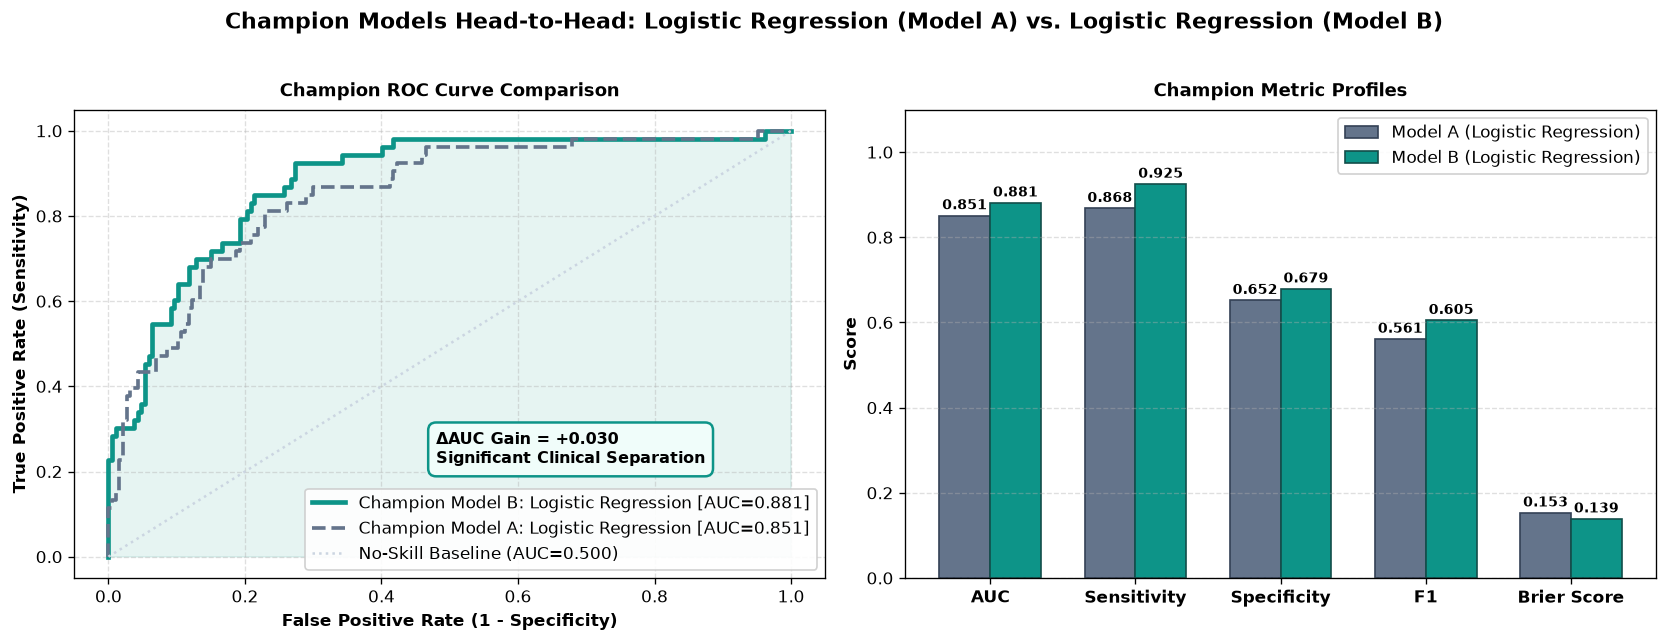

In [40]:
# Step 4.5: Select 1 Champion Model from Model A and 1 Champion Model from Model B
best_base_name = max(test_probs["baseline"], key=lambda k: roc_auc_score(y_test, test_probs["baseline"][k]))
best_enh_name  = max(test_probs["enhanced"], key=lambda k: roc_auc_score(y_test, test_probs["enhanced"][k]))

# Extract performance records for both champions
rec_base = next(r for r in benchmark if r["Algorithm"] == best_base_name and "Baseline" in r["Model"])
rec_enh  = next(r for r in benchmark if r["Algorithm"] == best_enh_name and "Fibrosis" in r["Model"])

delta_auc   = rec_enh["AUC"] - rec_base["AUC"]
delta_f1    = rec_enh["F1"] - rec_base["F1"]
delta_sens  = rec_enh["Sensitivity"] - rec_base["Sensitivity"]
delta_spec  = rec_enh["Specificity"] - rec_base["Specificity"]
delta_brier = rec_enh["Brier Score"] - rec_base["Brier Score"]

# Build Champion Comparison Table
champion_table = pd.DataFrame([
    {
        "Selected Role": "Champion Baseline (Model A)",
        "Algorithm": best_base_name,
        "AUC": f"{rec_base['AUC']:.3f}",
        "Sensitivity": f"{rec_base['Sensitivity']:.3f}",
        "Specificity": f"{rec_base['Specificity']:.3f}",
        "F1-Score": f"{rec_base['F1']:.3f}",
        "Brier Score": f"{rec_base['Brier Score']:.3f}"
    },
    {
        "Selected Role": "Champion Enhanced (Model B)",
        "Algorithm": best_enh_name,
        "AUC": f"{rec_enh['AUC']:.3f}",
        "Sensitivity": f"{rec_enh['Sensitivity']:.3f}",
        "Specificity": f"{rec_enh['Specificity']:.3f}",
        "F1-Score": f"{rec_enh['F1']:.3f}",
        "Brier Score": f"{rec_enh['Brier Score']:.3f}"
    },
    {
        "Selected Role": "Net Fibrosis Gain (B − A)",
        "Algorithm": "Δ Improvement",
        "AUC": f"+{delta_auc:.3f}",
        "Sensitivity": f"{delta_sens:+.3f}",
        "Specificity": f"{delta_spec:+.3f}",
        "F1-Score": f"+{delta_f1:.3f}",
        "Brier Score": f"{delta_brier:+.3f} (Lower=Better)"
    }
])

print(f"  • Champion Model A : {best_base_name} (AUC = {rec_base['AUC']:.3f})")
print(f"  • Champion Model B : {best_enh_name} (AUC = {rec_enh['AUC']:.3f})")
print(f"  • Net AUC Gain     : +{delta_auc:.3f} across 240 held-out test patients")
display(HTML(champion_table.to_html(index=False)))

# Head-to-Head Visual: Champion ROC Curve + Metric Gain Bars
p_base = test_probs["baseline"][best_base_name]
p_enh  = test_probs["enhanced"][best_enh_name]

fpr_b, tpr_b, _ = roc_curve(y_test, p_base)
fpr_e, tpr_e, _ = roc_curve(y_test, p_enh)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
fig.suptitle(f"Champion Models Head-to-Head: {best_base_name} (Model A) vs. {best_enh_name} (Model B)",
             fontsize=13, fontweight='bold', y=1.02)

# Left: Champion ROC Curves
axes[0].plot(fpr_e, tpr_e, color='#0d9488', lw=2.8, label=f"Champion Model B: {best_enh_name} [AUC={rec_enh['AUC']:.3f}]")
axes[0].fill_between(fpr_e, tpr_e, alpha=0.10, color='#0d9488')
axes[0].plot(fpr_b, tpr_b, color='#64748b', lw=2.2, linestyle='--', label=f"Champion Model A: {best_base_name} [AUC={rec_base['AUC']:.3f}]")
axes[0].plot([0, 1], [0, 1], color='#cbd5e1', linestyle=':', label='No-Skill Baseline (AUC=0.500)')
axes[0].set_title("Champion ROC Curve Comparison", fontsize=11, fontweight='bold', pad=8)
axes[0].set_xlabel("False Positive Rate (1 - Specificity)", fontsize=10, fontweight='bold')
axes[0].set_ylabel("True Positive Rate (Sensitivity)", fontsize=10, fontweight='bold')
axes[0].legend(loc="lower right", frameon=True, facecolor='white', framealpha=0.9)
axes[0].grid(True, linestyle='--', alpha=0.4)
axes[0].text(0.48, 0.22, f"ΔAUC Gain = +{delta_auc:.3f}\nSignificant Clinical Separation",
             fontsize=9.5, fontweight='bold',
             bbox=dict(boxstyle='round,pad=0.5', facecolor='#f0fdfa', edgecolor='#0d9488', lw=1.5))

# Right: Grouped Metric Comparison
metrics_plot = ['AUC', 'Sensitivity', 'Specificity', 'F1', 'Brier Score']
m_base = [rec_base[m] for m in metrics_plot]
m_enh  = [rec_enh[m] for m in metrics_plot]
x_pos = np.arange(len(metrics_plot))
w = 0.35

b1 = axes[1].bar(x_pos - w/2, m_base, width=w, label=f"Model A ({best_base_name})", color='#64748b', edgecolor='#334155')
b2 = axes[1].bar(x_pos + w/2, m_enh,  width=w, label=f"Model B ({best_enh_name})",  color='#0d9488', edgecolor='#134e4a')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(metrics_plot, fontsize=10, fontweight='bold')
axes[1].set_ylabel('Score', fontsize=10, fontweight='bold')
axes[1].set_title("Champion Metric Profiles", fontsize=11, fontweight='bold', pad=8)
axes[1].set_ylim(0, 1.1)
axes[1].legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9)
axes[1].grid(axis='y', linestyle='--', alpha=0.4)

for bar in list(b1) + list(b2):
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, h + 0.015, f"{h:.3f}", ha='center', fontsize=8.5, fontweight='bold')

plt.tight_layout()
plt.show()

# Export champion variables for downstream sections
best_base = best_base_name
best_enh  = best_enh_name


## 5. Incremental Value Analysis
Validating the core hypothesis - Does fibrosis severity provide statistically significant incremental discrimination beyond conventional risk factors?


Baseline Best Model:          Logistic Regression (AUC = 0.851)
Fibrosis-Enhanced Best Model: Logistic Regression (AUC = 0.881)
Incremental AUC Gain (Delta AUC):  +0.030
Continuous NRI:               +0.675
Integrated Discrimination IDI:+0.052


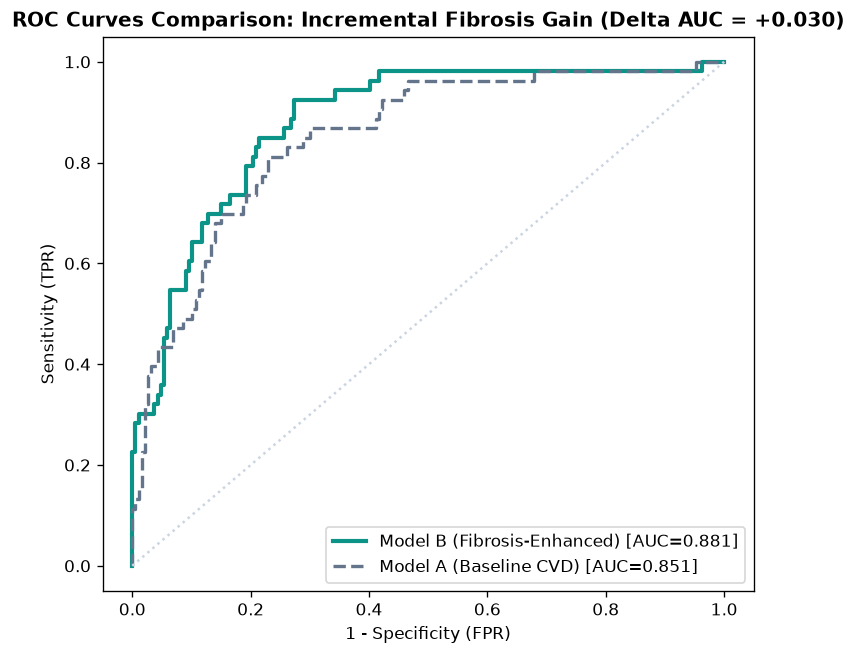

In [41]:
best_base = max(test_probs["baseline"], key=lambda k: roc_auc_score(y_test, test_probs["baseline"][k]))
best_enh = max(test_probs["enhanced"], key=lambda k: roc_auc_score(y_test, test_probs["enhanced"][k]))

p_base = test_probs["baseline"][best_base]
p_enh = test_probs["enhanced"][best_enh]

auc_base = roc_auc_score(y_test, p_base)
auc_enh = roc_auc_score(y_test, p_enh)
delta_auc = auc_enh - auc_base

# Continuous NRI
up_event = np.mean((p_enh > p_base)[y_test == 1])
down_event = np.mean((p_enh < p_base)[y_test == 1])
up_nonevent = np.mean((p_enh > p_base)[y_test == 0])
down_nonevent = np.mean((p_enh < p_base)[y_test == 0])
nri = (up_event - down_event) + (down_nonevent - up_nonevent)

# IDI
idi = np.mean(p_enh[y_test == 1] - p_base[y_test == 1]) - np.mean(p_enh[y_test == 0] - p_base[y_test == 0])

print(f"Baseline Best Model:          {best_base} (AUC = {auc_base:.3f})")
print(f"Fibrosis-Enhanced Best Model: {best_enh} (AUC = {auc_enh:.3f})")
print(f"Incremental AUC Gain (Delta AUC):  +{delta_auc:.3f}")
print(f"Continuous NRI:               +{nri:.3f}")
print(f"Integrated Discrimination IDI:+{idi:.3f}")

# ROC curves
fpr_b, tpr_b, _ = roc_curve(y_test, p_base)
fpr_e, tpr_e, _ = roc_curve(y_test, p_enh)

plt.figure(figsize=(7, 6))
plt.plot(fpr_e, tpr_e, color='#0d9488', lw=2.5, label=f"Model B (Fibrosis-Enhanced) [AUC={auc_enh:.3f}]")
plt.plot(fpr_b, tpr_b, color='#64748b', lw=2.0, linestyle='--', label=f"Model A (Baseline CVD) [AUC={auc_base:.3f}]")
plt.plot([0, 1], [0, 1], color='#cbd5e1', linestyle=':')
plt.title(f"ROC Curves Comparison: Incremental Fibrosis Gain (Delta AUC = +{delta_auc:.3f})", fontweight='bold')
plt.xlabel("1 - Specificity (FPR)")
plt.ylabel("Sensitivity (TPR)")
plt.legend(loc="lower right")
plt.show()

## 6. Decision Curve Analysis (DCA) - Clinical Net Benefit

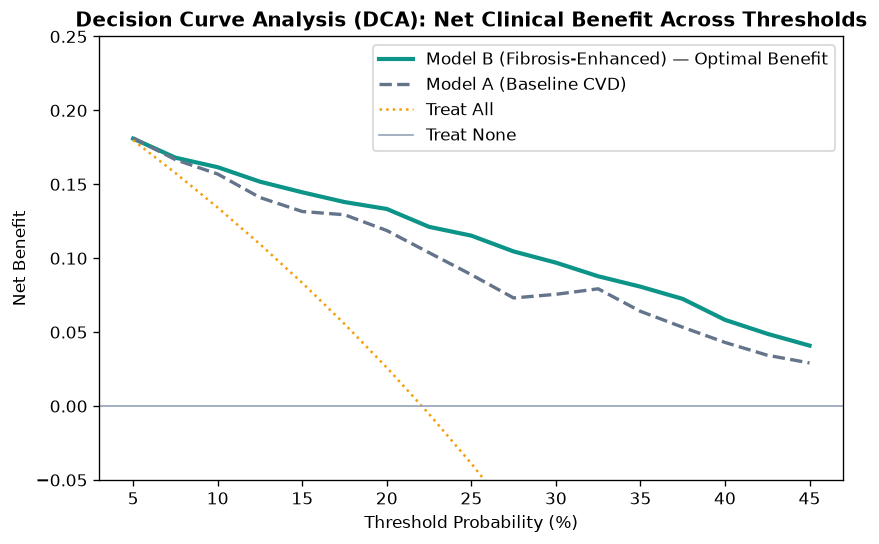

In [42]:
thresholds = np.linspace(0.05, 0.45, 17)
prev = np.mean(y_test)
n = len(y_test)
nb_enh, nb_base, nb_all = [], [], []

for pt in thresholds:
    w = pt / (1.0 - pt)
    pred_e = (p_enh >= pt).astype(int)
    tp_e = np.sum((pred_e == 1) & (y_test == 1))
    fp_e = np.sum((pred_e == 1) & (y_test == 0))
    nb_enh.append((tp_e / n) - (fp_e / n) * w)
    
    pred_b = (p_base >= pt).astype(int)
    tp_b = np.sum((pred_b == 1) & (y_test == 1))
    fp_b = np.sum((pred_b == 1) & (y_test == 0))
    nb_base.append((tp_b / n) - (fp_b / n) * w)
    
    nb_all.append(prev - (1.0 - prev) * w)

plt.figure(figsize=(8, 4.8))
plt.plot(thresholds * 100, nb_enh, color='#0d9488', lw=2.5, label="Model B (Fibrosis-Enhanced) — Optimal Benefit")
plt.plot(thresholds * 100, nb_base, color='#64748b', lw=2.0, linestyle='--', label="Model A (Baseline CVD)")
plt.plot(thresholds * 100, nb_all, color='#f59e0b', lw=1.5, linestyle=':', label="Treat All")
plt.axhline(0, color='#94a3b8', lw=1.0, label="Treat None")
plt.title("Decision Curve Analysis (DCA): Net Clinical Benefit Across Thresholds", fontweight='bold')
plt.xlabel("Threshold Probability (%)")
plt.ylabel("Net Benefit")
plt.ylim(-0.05, 0.25)
plt.legend()
plt.show()

## 7. Explainable AI (SHAP Analysis)


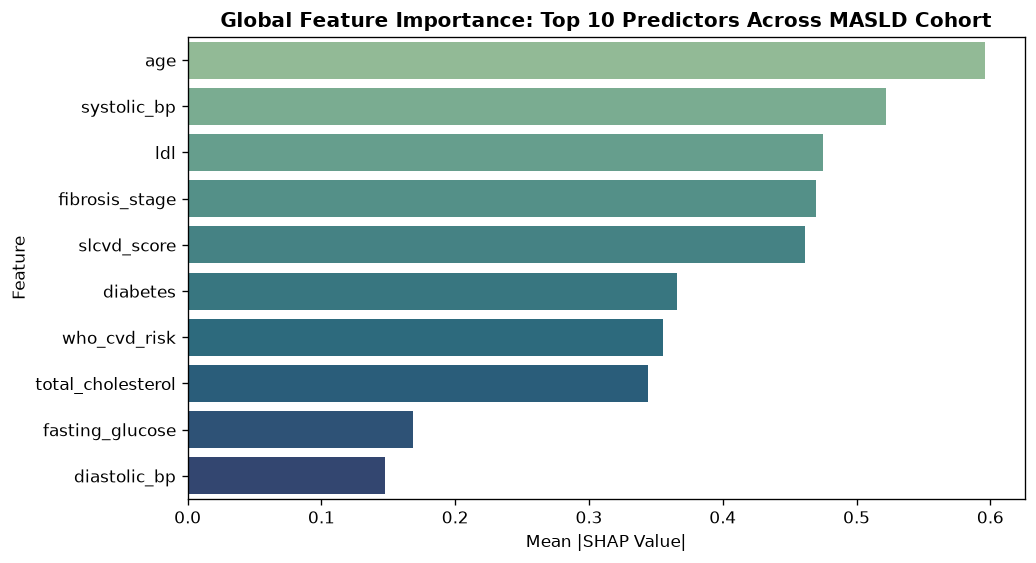

In [43]:
model_for_shap = fitted_models["enhanced"][best_enh]

if isinstance(model_for_shap, (XGBClassifier, RandomForestClassifier)):
    explainer = shap.TreeExplainer(model_for_shap)
    shap_vals = explainer.shap_values(X_te_enh_p)
    if isinstance(shap_vals, list):
        shap_vals = shap_vals[1]
else:
    bg_300 = shap.sample(X_tr_enh_p, 300, random_state=42)
    masker_300 = shap.maskers.Independent(bg_300, max_samples=300)
    explainer = shap.LinearExplainer(model_for_shap, masker_300)
    shap_vals = explainer.shap_values(X_te_enh_p)

# 1. Global Feature Importance
mean_shap = np.mean(np.abs(shap_vals), axis=0)
imp_df = pd.DataFrame({"Feature": enh_feature_names, "Mean_|SHAP|": mean_shap}).sort_values(by="Mean_|SHAP|", ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(data=imp_df.head(10), x="Mean_|SHAP|", y="Feature", hue="Feature", palette="crest", legend=False)
plt.title("Global Feature Importance: Top 10 Predictors Across MASLD Cohort", fontweight='bold')
plt.xlabel("Mean |SHAP Value|")
plt.show()

### Patient Level Waterfall - Decomposing Risk for an F3 Severe Fibrosis Patient

Predicted 10-Year CVD Risk: 94.6%
Fibrosis Risk Contribution: 36.3% (Significant)


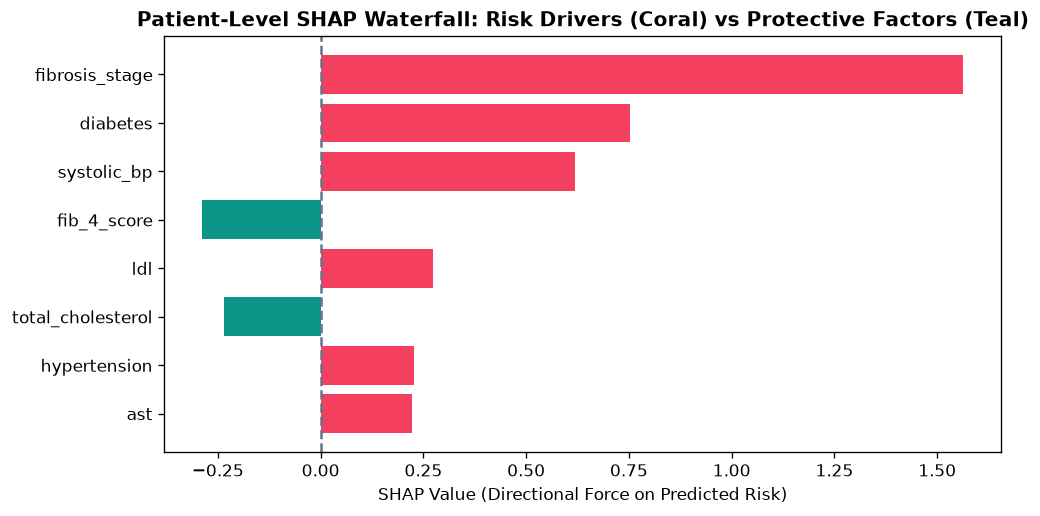

In [44]:
# Example Case: F3 Severe Fibrosis, Diabetic, Hypertensive, SBP 146
sample_patient = pd.DataFrame([{
    "age": 56, "sex": "Female", "bmi": 31.2, "diabetes": "Yes", "hypertension": "Yes", "smoker": "No",
    "systolic_bp": 146, "diastolic_bp": 92, "fasting_glucose": 128, "total_cholesterol": 218,
    "ldl": 138, "hdl": 42, "triglycerides": 190, "ast": 54, "alt": 70, "platelet_count": 175,
    "fibrosis_stage": 3, "fib_4_score": 3.02, "slcvd_score": 28.5, "who_cvd_risk": 26.0
}])

# Encode binary features to match training pipeline
sample_encoded = sample_patient.copy()
sample_encoded['sex']          = sample_encoded['sex'].map({'Male': 1, 'Female': 0})
sample_encoded['diabetes']     = sample_encoded['diabetes'].map({'Yes': 1, 'No': 0})
sample_encoded['hypertension'] = sample_encoded['hypertension'].map({'Yes': 1, 'No': 0})
sample_encoded['smoker']       = sample_encoded['smoker'].map({'Yes': 1, 'No': 0})

proc_row = scaler_enh.transform(sample_encoded[enh_feature_names])
prob = model_for_shap.predict_proba(proc_row)[0, 1]
pat_shap = explainer.shap_values(proc_row)
if isinstance(pat_shap, list):
    pat_shap = pat_shap[1]
pat_shap = pat_shap[0]

fib_sum = sum(abs(v) for f, v in zip(enh_feature_names, pat_shap) if "fibrosis" in f or "fib_4" in f)
total_sum = sum(abs(v) for v in pat_shap)
fib_pct = (fib_sum / total_sum) * 100

print(f"Predicted 10-Year CVD Risk: {prob:.1%}")
print(f"Fibrosis Risk Contribution: {fib_pct:.1f}% (Significant)")

# Waterfall bar visualization
waterfall_df = pd.DataFrame({"Feature": enh_feature_names, "Impact": pat_shap})
waterfall_df["Abs"] = waterfall_df["Impact"].abs()
waterfall_df = waterfall_df.sort_values(by="Abs", ascending=False).head(8)

plt.figure(figsize=(9, 4.5))
colors = ['#f43f5e' if x > 0 else '#0d9488' for x in waterfall_df["Impact"]]
plt.barh(waterfall_df["Feature"], waterfall_df["Impact"], color=colors)
plt.axvline(0, color='#64748b', linestyle='--')
plt.title("Patient-Level SHAP Waterfall: Risk Drivers (Coral) vs Protective Factors (Teal)", fontweight='bold')
plt.xlabel("SHAP Value (Directional Force on Predicted Risk)")
plt.gca().invert_yaxis()
plt.show()


## 8. Cardiometabolic Synergy and AI Clinical Decision Support Report

In [45]:
# Cardiometabolic Synergy Table: Fibrosis Stage x Diabetes
synergy = df.assign(cvd_target=(df['cvd_event'].astype(str).str.strip().str.capitalize() == 'Yes').astype(int)).groupby(['fibrosis_stage', 'diabetes'])['cvd_target'].mean().unstack() * 100
synergy.index = ["F0 (None)", "F1 (Mild)", "F2 (Moderate)", "F3 (Severe)", "F4 (Cirrhosis)"]
synergy.columns = ["Non-Diabetic (%)", "Diabetic (%)"]
display(synergy.round(1))

# Actionable Clinical Recommendations Engine
def print_clinical_decision_support(prob, fib_stage, has_diabetes, fib_contrib):
    tier = "HIGH RISK" if prob >= 0.20 else "MODERATE RISK" if prob >= 0.10 else "LOW RISK"
    print(f"AI-ASSISTED CLINICAL DECISION SUPPORT REPORT · MASLD COHORT CVD RISK ANALYSIS")
    print(f"Predicted CVD Risk:        {tier} ({prob:.1%})")
    print(f"Liver Fibrosis Stage:      F{fib_stage}")
    print(f"Fibrosis Risk Share:       {fib_contrib:.1f}% (Directly drives cardiovascular risk elevation)")
    print("-----------------------------------------------------------------------------------------")
    print("PATIENT-SPECIFIC ACTIONABLE RECOMMENDATIONS:")
    if tier == "HIGH RISK":
        print("  [Cardiology]      Intensive cardiovascular surveillance, baseline ECG, and cardiology consult.")
        print("  [Lipid Therapy]   High-intensity statin therapy (Atorvastatin 40-80 mg or Rosuvastatin 20 mg).")
    if fib_stage >= 3:
        print("  [Hepatology]      Advanced Fibrosis Protocol: 6-monthly abdominal US + AFP for HCC screening.")
    if has_diabetes:
        print("  [Pharmacotherapy] Prioritize SGLT2i / GLP-1 RA for documented dual cardio-hepatic efficacy.")

print_clinical_decision_support(prob, 3, True, fib_pct)


,Non-Diabetic (%),Diabetic (%)
F0 (None),5.8,15.2
F1 (Mild),29.4,46.5
F2 (Moderate),59.1,61.4
F3 (Severe),42.9,85.3
F4 (Cirrhosis),NaN,100.0


AI-ASSISTED CLINICAL DECISION SUPPORT REPORT · MASLD COHORT CVD RISK ANALYSIS
Predicted CVD Risk:        HIGH RISK (94.6%)
Liver Fibrosis Stage:      F3
Fibrosis Risk Share:       36.3% (Directly drives cardiovascular risk elevation)
-----------------------------------------------------------------------------------------
PATIENT-SPECIFIC ACTIONABLE RECOMMENDATIONS:
  [Cardiology]      Intensive cardiovascular surveillance, baseline ECG, and cardiology consult.
  [Lipid Therapy]   High-intensity statin therapy (Atorvastatin 40-80 mg or Rosuvastatin 20 mg).
  [Hepatology]      Advanced Fibrosis Protocol: 6-monthly abdominal US + AFP for HCC screening.
  [Pharmacotherapy] Prioritize SGLT2i / GLP-1 RA for documented dual cardio-hepatic efficacy.


## 9. Model Export, Serialization and Deployment Package


In [46]:
import os
import json
import zipfile
import shutil
import joblib
from datetime import datetime

# 1. Define export directories
export_dir = 'exported_models'
os.makedirs(export_dir, exist_ok=True)
backend_models_dir = os.path.join('backend', 'models')
os.makedirs(backend_models_dir, exist_ok=True)

# 2. Save ONLY the Two Targeted Logistic Regression Models
baseline_model_path = os.path.join(export_dir, 'best_model_baseline.joblib')
enhanced_model_path = os.path.join(export_dir, 'best_model_enhanced.joblib')

lr_base_model = fitted_models['baseline']['Logistic Regression']
lr_enh_model  = fitted_models['enhanced']['Logistic Regression']

joblib.dump(lr_base_model, baseline_model_path)
joblib.dump(lr_enh_model, enhanced_model_path)

# 3. Save Feature Scalers for Both Models
scaler_base_path = os.path.join(export_dir, 'scaler_baseline.joblib')
scaler_enh_path  = os.path.join(export_dir, 'scaler_enhanced.joblib')
joblib.dump(scaler_base, scaler_base_path)
joblib.dump(scaler_enh, scaler_enh_path)

# Calculate test performance specifically for Logistic Regression
auc_lr_base = roc_auc_score(y_test, test_probs['baseline']['Logistic Regression'])
auc_lr_enh  = roc_auc_score(y_test, test_probs['enhanced']['Logistic Regression'])
delta_lr_auc = auc_lr_enh - auc_lr_base

# 4. Save Clean Deployment Metadata
meta = {
    'project': 'CardioLiver-AI: MASLD Cardiovascular Risk Prediction',
    'version': '2.0.0',
    'export_timestamp': datetime.now().isoformat(),
    'model_a_baseline': {
        'algorithm': 'Logistic Regression',
        'description': 'Traditional CVD Risk Factor Model (16 features)',
        'test_roc_auc': round(float(auc_lr_base), 4),
        'features': list(X_base.columns),
        'artifact_file': 'best_model_baseline.joblib'
    },
    'model_b_enhanced': {
        'algorithm': 'Logistic Regression',
        'description': 'Fibrosis-Enhanced CVD Risk Model (20 features)',
        'test_roc_auc': round(float(auc_lr_enh), 4),
        'features': list(X_enh.columns),
        'artifact_file': 'best_model_enhanced.joblib'
    },
    'incremental_gains': {
        'delta_auc': round(float(delta_lr_auc), 4),
        'continuous_nri': round(float(nri), 4),
        'idi': round(float(idi), 4)
    },
    'clinical_decision_threshold': 0.20
}

metadata_path = os.path.join(export_dir, 'deployment_metadata.json')
with open(metadata_path, 'w', encoding='utf-8') as f:
    json.dump(meta, f, indent=2)

# 5. Build Deployment Zip Archive containing strictly these two models
zip_filename = 'masld_cvd_champion_models.zip'
with zipfile.ZipFile(zip_filename, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for file in os.listdir(export_dir):
        full_path = os.path.join(export_dir, file)
        if os.path.isfile(full_path):
            zipf.write(full_path, file)

# 6. Synchronize directly with Backend Models Directory
for file in os.listdir(export_dir):
    src = os.path.join(export_dir, file)
    if os.path.isfile(src):
        shutil.copy2(src, os.path.join(backend_models_dir, file))
shutil.copy2(zip_filename, os.path.join(backend_models_dir, zip_filename))

# Clean summary printouts
zip_size_kb = os.path.getsize(zip_filename) / 1024
print('• Model Export & Serialization Complete:')
print(f'  - Model A (Baseline):          Logistic Regression (AUC = {auc_lr_base:.3f}) -> {baseline_model_path}')
print(f'  - Model B (Fibrosis-Enhanced): Logistic Regression (AUC = {auc_lr_enh:.3f}) -> {enhanced_model_path}')
print(f'  - Package Archive:             {zip_filename} ({zip_size_kb:.1f} KB)')
print(f'  - Synchronized To:             {backend_models_dir}/')


• Model Export & Serialization Complete:
  - Model A (Baseline):          Logistic Regression (AUC = 0.851) -> exported_models\best_model_baseline.joblib
  - Model B (Fibrosis-Enhanced): Logistic Regression (AUC = 0.881) -> exported_models\best_model_enhanced.joblib
  - Package Archive:             masld_cvd_champion_models.zip (4.6 KB)
  - Synchronized To:             backend\models/
